# CSCI461 – Assignment #1: Dockerized Data, Text Analysis and Machine Learning

**Nile University · Introduction to Big Data · Fall 2026**

**Dataset:** UCI SMS Spam Collection (5,574 English SMS messages labelled `ham` or `spam`)
**Source:** <https://archive.ics.uci.edu/dataset/228/sms+spam+collection>

**Team members:** Ayham Ayman (231001290), Youssef Hisham (221000889), Mohamed Adel (231001166), Kareem Mahmoud (231001866)

### Pipeline
`Dockerfile → custom image → container → JupyterLab → data cleaning → sampling → text analysis → TF-IDF → classification + K-Means → persistent outputs (bind mount) → Docker Hub`

### Notebook outline
1. Setup and paths
2. Dataset understanding
3. Missing values and duplicates
4. `loc` / `iloc` selection
5. Feature engineering (transformations)
6. Sampling (simple random, stratified, cluster)
7. Correlation analysis
8. Text cleaning and tokenization
9. Word frequencies (with / without stop words)
10. Spam vs Ham comparison
11. Written insights
12. Supervised classification (Multinomial Naive Bayes vs Logistic Regression)
13. K-Means clustering
14. Saving outputs and final verification

> Run with **Kernel → Restart Kernel and Run All Cells**. Every output file is regenerated automatically under `output/`.

## 1. Setup and paths

In [1]:
# Standard library
import html
import platform
import re
import sys
from collections import Counter
from pathlib import Path

# Third-party libraries (all available in quay.io/jupyter/scipy-notebook + requirements.txt)
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    silhouette_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import Normalizer

# Reproducibility: one seed used everywhere
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---- Paths ---------------------------------------------------------------
# JupyterLab starts the kernel inside the notebook's folder (bd-a1/notebook),
# while `jupyter nbconvert` may start it from the project root. Resolve the
# project root robustly so the notebook works in both cases.
CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name == "notebook" else CWD
DATA_PATH = PROJECT_ROOT / "data" / "dataset.csv"
OUTPUT_DIR = PROJECT_ROOT / "output"
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)   # safe if the folder already exists

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH}. See README for download instructions.")

# ---- Plot style ----------------------------------------------------------
# Fixed colours per class so 'ham' and 'spam' look the same in every figure.
CLASS_COLORS = {"ham": "#2a78d6", "spam": "#eb6834"}
# Diverging map (blue -> neutral grey -> red) for correlation values in [-1, 1].
DIVERGING_CMAP = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "grid.alpha": 0.4})
pd.set_option("display.max_colwidth", 120)

print("Python      :", sys.version.split()[0], "|", platform.platform())
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)
print("Running inside Docker:", Path("/.dockerenv").exists())
print("Project root:", PROJECT_ROOT)
print("Dataset     :", DATA_PATH)
print("Outputs     :", OUTPUT_DIR)

Python      : 3.11.6 | Linux-6.18.44-fc-v185-x86_64-with-glibc2.35
pandas      : 2.1.1
numpy       : 1.24.4
scikit-learn: 1.3.1
matplotlib  : 3.8.0
Running inside Docker: True
Project root: /home/jovyan/bd-a1
Dataset     : /home/jovyan/bd-a1/data/dataset.csv
Outputs     : /home/jovyan/bd-a1/output


## 2. Dataset understanding

The original UCI file (`SMSSpamCollection`) is tab-separated with no header: `label<TAB>message`.
It was converted once on the host into `data/dataset.csv` with a header row (`label,message`) and standard CSV quoting,
**without changing any record** (see README → *Dataset*).

In [2]:
# Load the dataset. keep_default_na=False would hide real missing values, so we
# keep pandas' default NA detection and check for missing values explicitly below.
df_raw = pd.read_csv(DATA_PATH, encoding="utf-8")
df_raw.head(10)

,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...
6,ham,Even my brother is not like to speak with me. They treat me like aids patent.
7,ham,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Calle...
8,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 0906170146...
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call Th...


In [3]:
print("Shape (rows, columns):", df_raw.shape)
print("Columns:", list(df_raw.columns))
print("\nData types:")
print(df_raw.dtypes)

Shape (rows, columns): (5574, 2)
Columns: ['label', 'message']

Data types:
label      object
message    object
dtype: object


In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5574 non-null   object
 1   message  5574 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [5]:
# Descriptive statistics. Both raw columns are text (object), so describe() reports
# count / unique / top / freq instead of mean and standard deviation.
df_raw.describe(include="all")

,label,message
count,5574,5574
unique,2,5171
top,ham,"Sorry, I'll call later"
freq,4827,30


In [6]:
# Numerical view of the raw data: message length in characters, per class.
raw_lengths = df_raw.assign(char_len=df_raw["message"].astype(str).str.len())
raw_lengths.groupby("label")["char_len"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4827.0,71.47,58.33,2.0,33.0,52.0,93.0,910.0
spam,747.0,138.68,28.87,13.0,133.0,149.0,157.0,223.0


In [7]:
print("Class distribution (counts):")
print(df_raw["label"].value_counts())
print("\nClass distribution (proportions):")
print(df_raw["label"].value_counts(normalize=True).round(4))

Class distribution (counts):
label
ham     4827
spam     747
Name: count, dtype: int64

Class distribution (proportions):
label
ham     0.866
spam    0.134
Name: proportion, dtype: float64


**What does one row represent?** Each row is **one SMS message** collected from UK/Singapore mobile phone users
(Grumbletext forum, NUS SMS Corpus, Caroline Tag's thesis and the SMS Spam Corpus v0.1), together with a
human-assigned label saying whether the message is legitimate (`ham`) or unsolicited advertising/fraud (`spam`).

**Column roles**

| Column | Role | Notes |
|---|---|---|
| `message` | **Text** column | Free-form SMS text; the input for text analysis and machine learning. |
| `label` | **Categorical / label** column | Two classes (`ham`, `spam`); the supervised-learning target. |
| _(none in the raw file)_ | **Numerical** columns | The raw data has no numeric columns. Numerical features (`char_count`, `word_count`, …) are **engineered** from the text in Section 5. |

The class distribution is strongly **imbalanced** (≈ 87% ham / 13% spam), which affects sampling, metric choice and model evaluation later.

In [8]:
# Programmatic identification of column types (confirms the table above)
def describe_column_roles(frame: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for col in frame.columns:
        series = frame[col]
        if pd.api.types.is_numeric_dtype(series):
            role = "numerical"
        elif series.nunique() <= 10:
            role = "categorical / label"
        else:
            role = "text"
        rows.append({"column": col, "dtype": str(series.dtype), "n_unique": series.nunique(), "role": role})
    return pd.DataFrame(rows)

describe_column_roles(df_raw)

,column,dtype,n_unique,role
0,label,object,2,categorical / label
1,message,object,5171,text


## 3. Missing values and duplicates

In [9]:
# 3.1 Missing values per column (true NaN values)
missing_report = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2),
})
# Text can also be "missing" as an empty or whitespace-only string, which isna() does not catch
missing_report["empty_or_blank_strings"] = [
    (df_raw[col].astype(str).str.strip() == "").sum() for col in df_raw.columns
]
missing_report

,missing_count,missing_percent,empty_or_blank_strings
label,0,0.0,0
message,0,0.0,0


In [10]:
# 3.2 Label validity: every label should be exactly 'ham' or 'spam'
print("Distinct label values:", sorted(df_raw["label"].dropna().unique()))
invalid_labels = ~df_raw["label"].isin(["ham", "spam"])
print("Rows with an invalid/missing label:", int(invalid_labels.sum()))

Distinct label values: ['ham', 'spam']
Rows with an invalid/missing label: 0


In [11]:
# 3.3 Duplicates
full_row_dupes = df_raw.duplicated(keep="first")            # same label AND same message
message_dupes = df_raw.duplicated(subset="message", keep="first")  # same message text only

print("Exact duplicate rows (label + message):", int(full_row_dupes.sum()))
print("Duplicate message texts (ignoring label):", int(message_dupes.sum()))

# Do any identical messages carry conflicting labels?
labels_per_message = df_raw.groupby("message")["label"].nunique()
conflicting = labels_per_message[labels_per_message > 1]
print("Messages that appear with BOTH labels:", len(conflicting))

print("\nDuplicate rows by class:")
print(df_raw.loc[full_row_dupes, "label"].value_counts())

Exact duplicate rows (label + message): 403
Duplicate message texts (ignoring label): 403
Messages that appear with BOTH labels: 0

Duplicate rows by class:
label
ham     309
spam     94
Name: count, dtype: int64


In [12]:
# The most repeated messages
(df_raw.groupby(["label", "message"]).size()
       .sort_values(ascending=False)
       .head(8)
       .rename("occurrences")
       .reset_index())

,label,message,occurrences
0,ham,"Sorry, I'll call later",30
1,ham,I cant pick the phone right now. Pls send a message,12
2,ham,Ok...,10
3,ham,"Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing d...",4
4,ham,Ok,4
5,ham,"7 wonders in My WORLD 7th You 6th Ur style 5th Ur smile 4th Ur Personality 3rd Ur Nature 2nd Ur SMS and 1st ""Ur Love...",4
6,ham,Okie,4
7,ham,"Say this slowly.? GOD,I LOVE YOU &amp; I NEED YOU,CLEAN MY HEART WITH YOUR BLOOD.Send this to Ten special people &am...",4


**Cleaning decisions (and why)**

1. **Missing values.** The report above shows whether any `NaN` / blank values exist. The cleaning code is written to handle them
   anyway so the notebook stays correct if the file is ever changed:
   * rows with a **missing or invalid label** are **dropped** – a record without a target cannot be used for supervised learning and imputing a class would invent ground truth;
   * a **missing message** is converted to an empty string and then **dropped if empty**, because an empty SMS carries no information for text analysis.
2. **Labels** are normalised (`strip()` + `lower()`) so that values such as `" Spam"` would not create a third class.
3. **Exact duplicates** (same label and same text) are **removed, keeping the first occurrence**. Repeated messages are mostly
   bulk-sent spam and automatic replies; keeping them would (a) over-weight a few texts in word counts and correlations and,
   more importantly, (b) cause **data leakage** – the same message could appear in both the training and the test set,
   inflating test scores.
4. The **original `message` column is never modified**; text normalisation creates a new `cleaned_text` column in Section 8.

In [13]:
def clean_dataset(frame: pd.DataFrame) -> pd.DataFrame:
    # Return a cleaned copy of the raw SMS dataframe (the input is not modified).
    cleaned = frame.copy()

    # Normalise labels and drop rows whose label is missing or not ham/spam
    cleaned["label"] = cleaned["label"].astype("string").str.strip().str.lower()
    cleaned = cleaned[cleaned["label"].isin(["ham", "spam"])]

    # Missing text -> empty string, then drop messages that are empty/blank
    cleaned["message"] = cleaned["message"].fillna("").astype(str)
    cleaned = cleaned[cleaned["message"].str.strip() != ""]

    # Remove exact duplicate records, keeping the first occurrence
    cleaned = cleaned.drop_duplicates(subset=["label", "message"], keep="first")
    return cleaned.reset_index(drop=True)


shape_before = df_raw.shape
df = clean_dataset(df_raw)
shape_after = df.shape

print(f"Shape before cleaning: {shape_before}")
print(f"Shape after cleaning : {shape_after}")
print(f"Rows removed         : {shape_before[0] - shape_after[0]}")
print("\nClass distribution after cleaning:")
print(pd.concat([df["label"].value_counts(), df["label"].value_counts(normalize=True).round(4)],
                axis=1, keys=["count", "proportion"]))

Shape before cleaning: (5574, 2)
Shape after cleaning : (5171, 2)
Rows removed         : 403

Class distribution after cleaning:
       count  proportion
label                   
ham     4518      0.8737
spam     653      0.1263


## 4. Selection with `loc` and `iloc`

* `loc` selects by **label / boolean condition**.
* `iloc` selects by **integer position**; `np.r_` concatenates several position ranges into one index array.

In [14]:
# loc – meaningful conditional selection:
# long spam messages (> 150 characters) that ask the user to call or text a number.
long_call_to_action_spam = df.loc[
    (df["label"] == "spam")
    & (df["message"].str.len() > 150)
    & (df["message"].str.contains(r"\b(?:call|txt|text)\b", case=False, regex=True)),
    ["label", "message"],
]
print("Long call-to-action spam messages:", len(long_call_to_action_spam))
long_call_to_action_spam.head()

Long call-to-action spam messages: 232


,label,message
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
8,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 0906170146...
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call Th...
12,spam,"URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C ww..."
19,spam,"England v Macedonia - dont miss the goals/team news. Txt ur national team to 87077 eg ENGLAND to 87077 Try:WALES, SC..."


In [15]:
# loc – conditional selection + column subset: ham messages that contain a question mark
ham_questions = df.loc[(df["label"] == "ham") & df["message"].str.contains("?", regex=False), "message"]
print("Ham messages containing a question:", len(ham_questions))
ham_questions.head()

Ham messages containing a question: 1053


10              I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today.
20                                                                                  Is that seriously how you spell his name?
23                                   Aft i finish my lunch then i go str down lor. Ard 3 smth lor. U finish ur lunch already?
24                                                                  Ffffffffff. Alright no way I can meet up with you sooner?
27    Did you catch the bus ? Are you frying an egg ? Did you make a tea? Are you eating your mom's left over dinner ? Do ...
Name: message, dtype: object

In [16]:
# iloc – positional selection: rows 0-4, first column only (label)
df.iloc[0:5, 0]

0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: string

In [17]:
# iloc – rows 100..104 and both columns
df.iloc[100:105, :]

,label,message
100,ham,Please don't text me anymore. I have nothing else to say.
101,ham,Okay name ur price as long as its legal! Wen can I pick them up? Y u ave x ams xx
102,ham,I'm still looking for a car to buy. And have not gone 4the driving test yet.
103,ham,wow. You're right! I didn't mean to do that. I guess once i gave up on boston men and changed my search location to ...
104,ham,Umma my life and vava umma love you lot dear


In [18]:
# iloc with np.r_ – first 3 rows, rows 50-52 and the last 2 rows in ONE selection
positions = np.r_[0:3, 50:53, -2:0]
print("Selected positions:", positions)
df.iloc[positions]

Selected positions: [ 0  1  2 50 51 52 -2 -1]


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
50,ham,What you thinked about me. First time you saw me in class.
51,ham,"A gram usually runs like &lt;#&gt; , a half eighth is smarter though and gets you almost a whole second gram for &..."
52,ham,K fyi x has a ride early tomorrow morning but he's crashing at our place tonight
5169,ham,The guy did some bitching but I acted like i'd be interested in buying something else next week and he gave it to us...
5170,ham,Rofl. Its true to its name


In [19]:
# np.r_ can also be used for columns: here column positions [0, 1] combined explicitly
df.iloc[np.r_[10:13], np.r_[0, 1]]

,label,message
10,ham,"I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today."
11,spam,"SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs a..."
12,spam,"URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C ww..."


## 5. Feature engineering (transformations)

Transformations applied (at least three are required):

| # | Transformation | New column(s) | Why |
|---|---|---|---|
| 1 | **Type conversion** | `label` → `category` dtype | Saves memory and makes the two allowed values explicit. |
| 2 | **Label encoding** | `label_num` (ham = 0, spam = 1) | Numeric target required by scikit-learn and for correlation. |
| 3 | **Feature creation** | `char_count`, `word_count`, `unique_word_count`, `avg_word_length`, `digit_count`, `uppercase_ratio`, `exclamation_count`, `has_url` | Quantitative descriptions of each message. |
| 4 | **Binning** | `length_bin` (short / medium / long / very long) | Turns a skewed continuous length into interpretable groups. |
| 5 | **Normalization** | `char_count_minmax`, `word_count_zscore` | Puts features on comparable scales. |
| 6 | **Category consolidation** | `length_group` (short / long) | Merges the four length bins into two broader groups. |

Text-statistic features are computed on the **original** message (split on whitespace) so that they describe what the recipient actually sees.

In [20]:
# 1) Type conversion: label -> categorical dtype with a fixed category order
df["label"] = pd.Categorical(df["label"], categories=["ham", "spam"])

# 2) Label encoding: ham -> 0, spam -> 1
df["label_num"] = df["label"].cat.codes.astype("int64")
print(df[["label", "label_num"]].drop_duplicates().sort_values("label_num").to_string(index=False))
print("\nlabel dtype:", df["label"].dtype, "| label_num dtype:", df["label_num"].dtype)

label  label_num
  ham          0
 spam          1

label dtype: category | label_num dtype: int64


In [21]:
# 3) Feature creation – numerical text features from the ORIGINAL message
raw_words = df["message"].str.split()               # whitespace tokenisation

df["char_count"] = df["message"].str.len()
df["word_count"] = raw_words.str.len()
df["unique_word_count"] = raw_words.apply(lambda words: len({w.lower() for w in words}))
# Average word length = letters/characters in words / number of words (0 if no words)
df["avg_word_length"] = raw_words.apply(lambda words: np.mean([len(w) for w in words]) if words else 0.0)
df["digit_count"] = df["message"].str.count(r"\d")
letters = df["message"].str.count(r"[A-Za-z]")
df["uppercase_ratio"] = (df["message"].str.count(r"[A-Z]") / letters.replace(0, np.nan)).fillna(0.0)
df["exclamation_count"] = df["message"].str.count("!")
df["has_url"] = df["message"].str.contains(r"https?://|www\.|\.com\b|\.co\.uk\b", case=False, regex=True).astype(int)

text_features = ["char_count", "word_count", "unique_word_count", "avg_word_length",
                 "digit_count", "uppercase_ratio", "exclamation_count", "has_url"]
df[text_features].describe().round(3)

,char_count,word_count,unique_word_count,avg_word_length,digit_count,uppercase_ratio,exclamation_count,has_url
count,5171.000,5171.000,5171.000,5171.000,5171.000,5171.000,5171.000,5171.000
mean,79.332,15.434,14.266,4.253,2.215,0.088,0.243,0.024
std,58.333,11.102,9.066,1.142,6.030,0.151,0.679,0.154
min,2.000,1.000,1.000,1.500,0.000,0.000,0.000,0.000
25%,36.000,7.000,7.000,3.667,0.000,0.033,0.000,0.000
50%,61.000,12.000,12.000,4.097,0.000,0.048,0.000,0.000
75%,119.000,22.000,21.000,4.643,1.000,0.077,0.000,0.000
max,910.000,171.000,100.000,49.000,47.000,1.000,11.000,1.000


In [22]:
# 4) Binning – message length (characters) into four interpretable bins.
#    Edges follow common SMS limits: 160 chars = one standard SMS segment.
length_edges = [0, 40, 100, 160, np.inf]
length_labels = ["short (<=40)", "medium (41-100)", "long (101-160)", "very long (>160)"]
df["length_bin"] = pd.cut(df["char_count"], bins=length_edges, labels=length_labels, right=True)

# 6) Category consolidation – merge the four bins into two broader groups
consolidation_map = {
    "short (<=40)": "short (<=100)", "medium (41-100)": "short (<=100)",
    "long (101-160)": "long (>100)", "very long (>160)": "long (>100)",
}
df["length_group"] = df["length_bin"].map(consolidation_map).astype("category")

print("Messages per length bin and class:")
print(pd.crosstab(df["length_bin"], df["label"], margins=True))
print("\nSpam share per consolidated group:")
print(pd.crosstab(df["length_group"], df["label"], normalize="index").round(3))

Messages per length bin and class:
label              ham  spam   All
length_bin                        
short (<=40)      1608     9  1617
medium (41-100)   1913    64  1977
long (101-160)     805   527  1332
very long (>160)   192    53   245
All               4518   653  5171

Spam share per consolidated group:
label            ham   spam
length_group               
long (>100)    0.632  0.368
short (<=100)  0.980  0.020


In [23]:
# 5) Normalization
#    Min-max scaling maps char_count to [0, 1]; z-score standardises word_count to mean 0, std 1.
#    (These columns are for analysis only; the ML pipelines below build their own features from text.)
cc_min, cc_max = df["char_count"].min(), df["char_count"].max()
df["char_count_minmax"] = (df["char_count"] - cc_min) / (cc_max - cc_min)
df["word_count_zscore"] = (df["word_count"] - df["word_count"].mean()) / df["word_count"].std(ddof=0)

df[["char_count", "char_count_minmax", "word_count", "word_count_zscore"]].describe().round(3)

,char_count,char_count_minmax,word_count,word_count_zscore
count,5171.000,5171.000,5171.000,5171.000
mean,79.332,0.085,15.434,-0.000
std,58.333,0.064,11.102,1.000
min,2.000,0.000,1.000,-1.300
25%,36.000,0.037,7.000,-0.760
50%,61.000,0.065,12.000,-0.309
75%,119.000,0.129,22.000,0.592
max,910.000,1.000,171.000,14.014


In [24]:
df.head()

,label,message,label_num,char_count,word_count,unique_word_count,avg_word_length,digit_count,uppercase_ratio,exclamation_count,has_url,length_bin,length_group,char_count_minmax,word_count_zscore
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",0,111,20,20,4.600000,0,0.036145,0,0,long (101-160),long (>100),0.120044,0.411336
1,ham,Ok lar... Joking wif u oni...,0,29,6,6,4.000000,0,0.111111,0,0,short (<=40),short (<=100),0.029736,-0.849813
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,1,155,28,24,4.571429,25,0.103093,0,0,long (101-160),long (>100),0.168502,1.131993
3,ham,U dun say so early hor... U c already then say...,0,49,11,10,3.545455,0,0.060606,0,0,medium (41-100),short (<=100),0.051762,-0.399403
4,ham,"Nah I don't think he goes to usf, he lives around here though",0,61,13,12,3.769231,0,0.042553,0,0,medium (41-100),short (<=100),0.064978,-0.219239


## 6. Sampling

Three probability-sampling methods, each drawing roughly **20%** of the cleaned data:

* **Simple random sampling (SRS):** every message has the same chance of selection, independent of class.
* **Stratified sampling:** the population is split into strata (`ham`, `spam`) and 20% is drawn **from each stratum**, so class proportions are preserved by design.
* **Cluster sampling:** the population is divided into groups (*clusters*) and **whole clusters** are selected at random; every message in a chosen cluster is included.
  The SMS file has no natural grouping column, so we form clusters as **consecutive blocks of 50 messages in file order** (similar to pages of a log file) and randomly select 20% of the blocks.

In [25]:
SAMPLE_FRACTION = 0.20

# Simple random sample
srs_sample = df.sample(frac=SAMPLE_FRACTION, random_state=RANDOM_STATE)

# Stratified sample: same fraction within each label group
stratified_sample = (df.groupby("label", observed=True, group_keys=False)
                       .sample(frac=SAMPLE_FRACTION, random_state=RANDOM_STATE))

# Cluster sample: blocks of 50 consecutive records = clusters; pick 20% of the clusters entirely
CLUSTER_SIZE = 50
df["sampling_cluster"] = np.arange(len(df)) // CLUSTER_SIZE
cluster_ids = df["sampling_cluster"].unique()
rng = np.random.default_rng(RANDOM_STATE)
n_clusters_to_pick = int(round(SAMPLE_FRACTION * len(cluster_ids)))
chosen_clusters = rng.choice(cluster_ids, size=n_clusters_to_pick, replace=False)
cluster_sample = df[df["sampling_cluster"].isin(chosen_clusters)]

print(f"Population size      : {len(df)}")
print(f"SRS sample size      : {len(srs_sample)}")
print(f"Stratified size      : {len(stratified_sample)}")
print(f"Cluster sample size  : {len(cluster_sample)}  ({n_clusters_to_pick} of {len(cluster_ids)} clusters)")

Population size      : 5171
SRS sample size      : 1034
Stratified size      : 1035
Cluster sample size  : 1050  (21 of 104 clusters)


In [26]:
# Compare class distributions (percentage of spam / ham) across population and samples
def class_share(frame: pd.DataFrame) -> pd.Series:
    return frame["label"].value_counts(normalize=True).reindex(["ham", "spam"]).mul(100)

sampling_comparison = pd.DataFrame({
    "Original (cleaned)": class_share(df),
    "Simple random": class_share(srs_sample),
    "Stratified": class_share(stratified_sample),
    "Cluster": class_share(cluster_sample),
}).T.round(2)
sampling_comparison.columns = ["ham %", "spam %"]
sampling_comparison["n"] = [len(df), len(srs_sample), len(stratified_sample), len(cluster_sample)]
sampling_comparison["spam % deviation from original"] = (
    sampling_comparison["spam %"] - sampling_comparison.loc["Original (cleaned)", "spam %"]).round(2)
sampling_comparison

,ham %,spam %,n,spam % deviation from original
Original (cleaned),87.37,12.63,5171,0.00
Simple random,86.75,13.25,1034,0.62
Stratified,87.34,12.66,1035,0.03
Cluster,87.24,12.76,1050,0.13


Spam % per cluster: min = 4.0, max = 24.0, std = 4.1


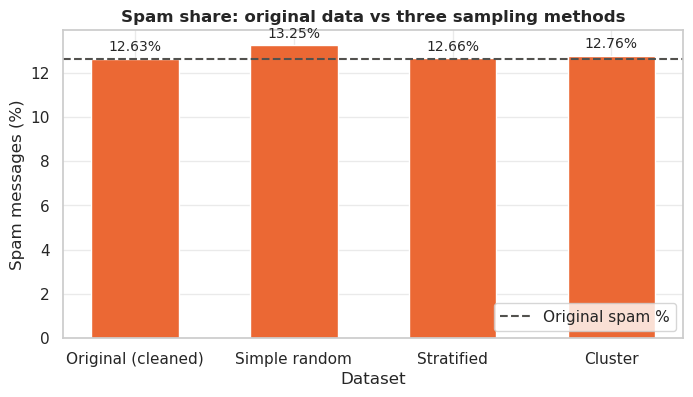

In [27]:
# Spread of the spam share across the individual clusters explains why cluster sampling is less precise
spam_share_per_cluster = df.groupby("sampling_cluster")["label_num"].mean().mul(100)
print("Spam % per cluster: min = {:.1f}, max = {:.1f}, std = {:.1f}".format(
    spam_share_per_cluster.min(), spam_share_per_cluster.max(), spam_share_per_cluster.std()))

fig, ax = plt.subplots(figsize=(8, 4))
plot_df = sampling_comparison[["spam %"]].reset_index().rename(columns={"index": "dataset"})
ax.bar(plot_df["dataset"], plot_df["spam %"], color=CLASS_COLORS["spam"], width=0.55)
ax.axhline(sampling_comparison.loc["Original (cleaned)", "spam %"], color="#52514e", ls="--", lw=1.5,
           label="Original spam %")
for i, value in enumerate(plot_df["spam %"]):
    ax.text(i, value + 0.2, f"{value:.2f}%", ha="center", va="bottom", fontsize=10)
ax.set_title("Spam share: original data vs three sampling methods")
ax.set_ylabel("Spam messages (%)")
ax.set_xlabel("Dataset")
ax.legend(loc="lower right")
fig.savefig(FIG_DIR / "06_sampling_comparison.png")
plt.show()

In [28]:
# One sample can be lucky or unlucky. To compare the methods fairly, repeat each one 300 times with
# different seeds and look at how much the spam share varies (standard deviation = sampling error).
N_REPEATS = 300
repeat_rows = []
for seed in range(N_REPEATS):
    srs = df.sample(frac=SAMPLE_FRACTION, random_state=seed)
    strat = df.groupby("label", observed=True, group_keys=False).sample(frac=SAMPLE_FRACTION, random_state=seed)
    picked = np.random.default_rng(seed).choice(cluster_ids, size=n_clusters_to_pick, replace=False)
    clus = df[df["sampling_cluster"].isin(picked)]
    for method, sample in [("Simple random", srs), ("Stratified", strat), ("Cluster", clus)]:
        repeat_rows.append({"method": method, "spam %": 100 * sample["label_num"].mean()})

repeat_summary = (pd.DataFrame(repeat_rows).groupby("method")["spam %"]
                    .agg(mean="mean", std="std", min="min", max="max")
                    .reindex(["Simple random", "Stratified", "Cluster"]).round(3))
print(f"Population spam % = {100 * df['label_num'].mean():.3f}")
repeat_summary

Population spam % = 12.628


,mean,std,min,max
method,,,,
Simple random,12.630,0.907,10.542,14.990
Stratified,12.657,0.000,12.657,12.657
Cluster,12.558,0.790,10.286,14.857


**Differences among the three methods**

* **Simple random sampling** is unbiased on average, but the class mix of a single sample can drift from the population purely by chance. With a minority class of only ~12%, a small sample can noticeably over- or under-represent spam.
* **Stratified sampling** fixes the proportion in each stratum, so its spam share matches the population almost exactly (up to rounding). It is the best choice when a minority class must be represented reliably – this is why the train/test split in Section 12 is stratified.
* **Cluster sampling** is the cheapest to collect in practice (take whole blocks/pages/days). Its precision depends on how similar the clusters are to each other. If each cluster is a near-random mix of the population, it behaves like SRS. If clusters are internally homogeneous (e.g. one block = one spam campaign), it is much less precise. Its sample size is also not fixed (it depends on which blocks are chosen).

**Reading the results.**
* *Single samples (seed 42):* the stratified sample matches the population spam share almost exactly (deviation 0.03 points). The simple random sample deviates the most (+0.62 points), and the cluster sample deviates +0.13 points.
* *Repeated experiment (300 draws per method):* stratified sampling has **zero spread** (std 0.000), because the strata fix the class counts. Simple random sampling has std **0.907** percentage points. Cluster sampling has std **0.790**, similar to SRS.
* *Why cluster sampling is not worse here:* the spam share per block of 50 messages varies (4%–24%). However, the file is **not ordered by class**, so consecutive blocks are close to random mixtures. With 21 blocks per sample, the between-block variation averages out to roughly the same precision as SRS. With clusters that group similar messages (same sender, same day, same campaign), cluster sampling would be clearly less precise than SRS.
* *Conclusion:* stratified sampling is the most reliable method for preserving the minority-class proportion. This is why the train/test split in Section 12 uses `stratify=y`.

## 7. Correlation analysis

In [29]:
correlation_features = ["char_count", "word_count", "unique_word_count", "avg_word_length",
                        "digit_count", "uppercase_ratio", "exclamation_count", "label_num"]
corr_matrix = df[correlation_features].corr(method="pearson")
corr_matrix.round(3)

,char_count,word_count,unique_word_count,avg_word_length,digit_count,uppercase_ratio,exclamation_count,label_num
char_count,1.000,0.974,0.964,0.085,0.379,0.066,0.251,0.381
word_count,0.974,1.000,0.981,-0.068,0.284,0.046,0.232,0.284
unique_word_count,0.964,0.981,1.000,-0.058,0.337,0.059,0.247,0.337
avg_word_length,0.085,-0.068,-0.058,1.000,0.229,0.040,0.057,0.241
digit_count,0.379,0.284,0.337,0.229,1.000,0.213,0.260,0.837
uppercase_ratio,0.066,0.046,0.059,0.040,0.213,1.000,0.204,0.197
exclamation_count,0.251,0.232,0.247,0.057,0.260,0.204,1.000,0.255
label_num,0.381,0.284,0.337,0.241,0.837,0.197,0.255,1.000


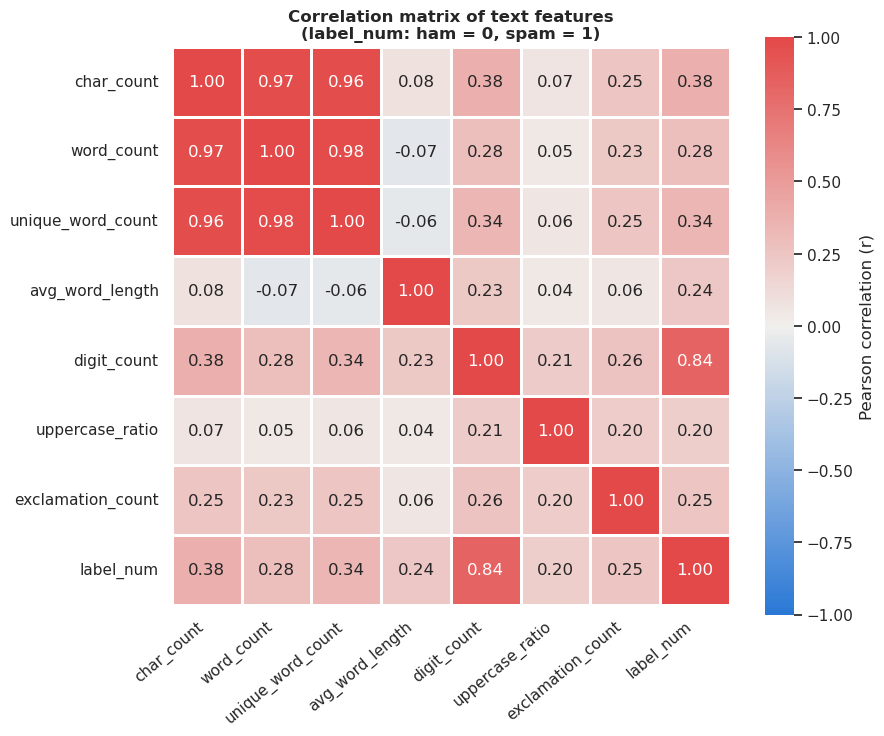

In [30]:
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap=DIVERGING_CMAP, vmin=-1, vmax=1, center=0,
            square=True, linewidths=2, linecolor="white", cbar_kws={"label": "Pearson correlation (r)"}, ax=ax)
ax.set_title("Correlation matrix of text features\n(label_num: ham = 0, spam = 1)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
fig.savefig(FIG_DIR / "01_correlation_heatmap.png")
plt.show()

In [31]:
# Rank all feature pairs by absolute correlation to support the interpretation
pair_rows = [
    {"feature_1": a, "feature_2": b, "r": corr_matrix.loc[a, b]}
    for i, a in enumerate(correlation_features) for b in correlation_features[i + 1:]
]
pairs = pd.DataFrame(pair_rows)
pairs["|r|"] = pairs["r"].abs()
pairs["strength"] = pd.cut(pairs["|r|"], bins=[0, 0.3, 0.7, 1.0], labels=["weak", "moderate", "strong"],
                           include_lowest=True)
print("Strongest relationships:")
print(pairs.sort_values("|r|", ascending=False).head(6).round(3).to_string(index=False))
print("\nWeakest relationships:")
print(pairs.sort_values("|r|").head(5).round(3).to_string(index=False))
print("\nCorrelation of each feature with the spam label (label_num):")
print(corr_matrix["label_num"].drop("label_num").sort_values(ascending=False).round(3).to_string())

Strongest relationships:
  feature_1         feature_2     r   |r| strength
 word_count unique_word_count 0.981 0.981   strong
 char_count        word_count 0.974 0.974   strong
 char_count unique_word_count 0.964 0.964   strong
digit_count         label_num 0.837 0.837   strong
 char_count         label_num 0.381 0.381 moderate
 char_count       digit_count 0.379 0.379 moderate

Weakest relationships:
        feature_1         feature_2      r   |r| strength
  avg_word_length   uppercase_ratio  0.040 0.040     weak
       word_count   uppercase_ratio  0.046 0.046     weak
  avg_word_length exclamation_count  0.057 0.057     weak
unique_word_count   avg_word_length -0.058 0.058     weak
unique_word_count   uppercase_ratio  0.059 0.059     weak

Correlation of each feature with the spam label (label_num):
digit_count          0.837
char_count           0.381
unique_word_count    0.337
word_count           0.284
exclamation_count    0.255
avg_word_length      0.241
uppercase_ratio      0

**Interpretation** (values from the heatmap / ranked table above)

* **Strong positive** correlations exist among `char_count`, `word_count` and `unique_word_count` (r ≈ 0.96–0.98). This is expected: they all
  measure *message size* – longer messages contain more words and more distinct words. They are largely **redundant**, so using all
  of them in a linear model adds little new information (multicollinearity).
* `digit_count` has by far the **strongest relationship with the spam label** (r ≈ 0.84), followed by `char_count` (r ≈ 0.38, moderate).
  Spam typically contains phone numbers, short codes and prices.
* `avg_word_length` is only **weakly** correlated with the counts: message length does not determine how long the individual words are.
* `uppercase_ratio` and `exclamation_count` have only **weak** positive correlations with spam (r ≈ 0.2–0.26): shouting ("FREE!", "WINNER!!") occurs in spam, but plenty of ham is also written in capitals or with exclamation marks.
* `digit_count` is only moderately related to message length (r ≈ 0.3–0.4), so it carries information that the length features do not.

**Correlation does not imply causation.** A high correlation between `digit_count` and `label_num` does **not** mean that adding digits
*causes* a message to be spam. Both are consequences of a third factor – the *purpose* of the message (marketing a premium-rate service
requires a number to call). Correlation is also only a measure of **linear** association, can be driven by outliers, and says nothing
about direction. Establishing causation would require controlled experiments or causal modelling, not observational counts.

## 8. Text cleaning and tokenization

A new `cleaned_text` column is created; the original `message` column is left **unchanged**.

Cleaning steps (in order):
1. **Missing text** → empty string (defensive; `NaN` would otherwise crash string functions).
2. **HTML entities** are decoded (the corpus contains `&lt;#&gt;` and `&amp;` placeholders).
3. **Lower-casing.**
4. **URLs** (`http://…`, `www.…`) → token `url`; **e-mail addresses** → `email`.
5. **Numbers:** long digit sequences (≥ 5 digits, typically phone numbers / short codes) → `phonenum`; other numbers → `num`.
   Numbers are *replaced* rather than deleted because their presence is a strong spam signal, while their exact values are not.
6. **Currency symbols** (`£`, `$`, `€`) → `currency` (prices are frequent in spam).
7. **Punctuation and other symbols** removed (apostrophes are dropped so that *don't* → *dont*).
8. **Extra whitespace** collapsed and trimmed.

In [32]:
URL_PATTERN = re.compile(r"(https?://\S+|www\.\S+|\b\S+\.(?:com|co\.uk|net|org|biz)\S*)")
EMAIL_PATTERN = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.]+\b")
LONG_NUMBER_PATTERN = re.compile(r"\d{5,}")
NUMBER_PATTERN = re.compile(r"\d+(?:[.,]\d+)?")
CURRENCY_PATTERN = re.compile(r"[£$€]")
NON_LETTER_PATTERN = re.compile(r"[^a-z\s]")
WHITESPACE_PATTERN = re.compile(r"\s+")


def clean_text(text) -> str:
    # Normalise one SMS message for text analysis; returns '' for missing input.
    if text is None or (isinstance(text, float) and np.isnan(text)):
        return ""
    text = html.unescape(str(text))                     # &lt; -> <, &amp; -> &
    text = text.lower()
    text = EMAIL_PATTERN.sub(" email ", text)           # before URLs: emails contain dots too
    text = URL_PATTERN.sub(" url ", text)
    text = CURRENCY_PATTERN.sub(" currency ", text)
    text = LONG_NUMBER_PATTERN.sub(" phonenum ", text)
    text = NUMBER_PATTERN.sub(" num ", text)
    text = text.replace("'", "").replace("’", "")       # don't -> dont
    text = NON_LETTER_PATTERN.sub(" ", text)            # remove remaining punctuation/symbols
    return WHITESPACE_PATTERN.sub(" ", text).strip()


# Quick unit checks of edge cases
assert clean_text(np.nan) == ""
assert clean_text(None) == ""
assert clean_text("  WIN £1000!!! Call 09061701461 now  ") == "win currency num call phonenum now"
assert clean_text("Visit www.example.com or http://x.co.uk/a") == "visit url or url"
assert clean_text("I don't know &lt;#&gt; ") == "i dont know"

original_messages = df["message"].copy()               # snapshot to prove the original stays unchanged
df["cleaned_text"] = df["message"].apply(clean_text)
assert df["message"].equals(original_messages), "Original text column was modified!"

print("Messages that became empty after cleaning:", int((df["cleaned_text"] == "").sum()))
df[["label", "message", "cleaned_text"]].sample(8, random_state=RANDOM_STATE)

Messages that became empty after cleaning: 2


,label,message,cleaned_text
1566,ham,"K, makes sense, btw carlos is being difficult so you guys are gonna smoke while I go pick up the second batch and ge...",k makes sense btw carlos is being difficult so you guys are gonna smoke while i go pick up the second batch and get gas
1988,spam,"URGENT! Your mobile No *********** WON a £2,000 Bonus Caller Prize on 02/06/03! This is the 2nd attempt to reach YOU...",urgent your mobile no won a currency num bonus caller prize on num num num this is the num nd attempt to reach you c...
1235,ham,If you still havent collected the dough pls let me know so i can go to the place i sent it to get the control number,if you still havent collected the dough pls let me know so i can go to the place i sent it to get the control number
2868,ham,Wat time do u wan 2 meet me later?,wat time do u wan num meet me later
4903,ham,Its too late:)but its k.wish you the same.,its too late but its k wish you the same
1471,ham,Check wid corect speling i.e. Sarcasm,check wid corect speling i e sarcasm
1129,ham,Hey! There's veggie pizza... :/,hey theres veggie pizza
5022,ham,So how many days since then?,so how many days since then


In [33]:
# Tokenization: split cleaned text on whitespace (punctuation is already removed)
df["tokens"] = df["cleaned_text"].str.split()
all_tokens = [token for tokens in df["tokens"] for token in tokens]

total_tokens = len(all_tokens)
unique_words = len(set(all_tokens))
avg_words_per_record = df["tokens"].str.len().mean()

print(f"Total tokens            : {total_tokens:,}")
print(f"Unique words (vocabulary): {unique_words:,}")
print(f"Average words per record : {avg_words_per_record:.2f}")
print(f"Type/token ratio         : {unique_words / total_tokens:.3f}")

Total tokens            : 81,818
Unique words (vocabulary): 7,775
Average words per record : 15.82
Type/token ratio         : 0.095


## 9. Word frequencies (before and after stop-word removal)

In [34]:
word_counts = Counter(all_tokens)
top20_all = pd.DataFrame(word_counts.most_common(20), columns=["word", "frequency"])
top20_all.index = np.arange(1, 21)
top20_all["share_of_tokens_%"] = (top20_all["frequency"] / total_tokens * 100).round(2)

# Stop words: scikit-learn's built-in English list (no internet download needed inside Docker)
STOP_WORDS = set(ENGLISH_STOP_WORDS)
top20_all["is_stop_word"] = top20_all["word"].isin(STOP_WORDS)
print(f"Stop words among the top-20 words: {top20_all['is_stop_word'].sum()} / 20")
top20_all

Stop words among the top-20 words: 17 / 20


,word,frequency,share_of_tokens_%,is_stop_word
1,num,3152,3.85,False
2,i,2266,2.77,True
3,to,2080,2.54,True
4,you,2061,2.52,True
5,a,1325,1.62,True
6,the,1249,1.53,True
7,u,1071,1.31,False
8,and,930,1.14,True
9,in,835,1.02,True
10,is,799,0.98,True


Stop words (*i, you, to, the, a, …*) dominate the raw ranking, so they hide the content words. We therefore remove scikit-learn's English
stop-word list and compare the two rankings. Note that SMS shorthand such as `u`, `ur`, `im` is **not** in a standard stop-word list,
so it stays in the filtered ranking – that is itself a characteristic of SMS language.

In [35]:
content_tokens = [token for token in all_tokens if token not in STOP_WORDS]
content_counts = Counter(content_tokens)
top20_content = pd.DataFrame(content_counts.most_common(20), columns=["word", "frequency"])
top20_content.index = np.arange(1, 21)

print(f"Tokens after stop-word removal: {len(content_tokens):,} "
      f"({len(content_tokens) / total_tokens:.1%} of all tokens kept)")
comparison_table = pd.concat([top20_all[["word", "frequency"]], top20_content], axis=1,
                             keys=["With stop words", "Stop words removed"])
comparison_table

Tokens after stop-word removal: 46,251 (56.5% of all tokens kept)


With stop words           Stop words removed          
              word frequency               word frequency
1              num      3152                num      3152
2                i      2266                  u      1071
3               to      2080           phonenum       645
4              you      2061                 im       464
5                a      1325               just       350
6              the      1249                 ur       322
7                u      1071           currency       295
8              and       930               dont       269
9               in       835                 ok       260
10              is       799               free       253
11              me       758               know       244
12              my       691               like       236
13             for       666                got       234
14        phonenum       645               good       229
15            your       622               come       216
16              it       597               time       211
17              of       561                day       209
18            have       541               love       195
19            call       514               want       191
20            that       511                ill       180

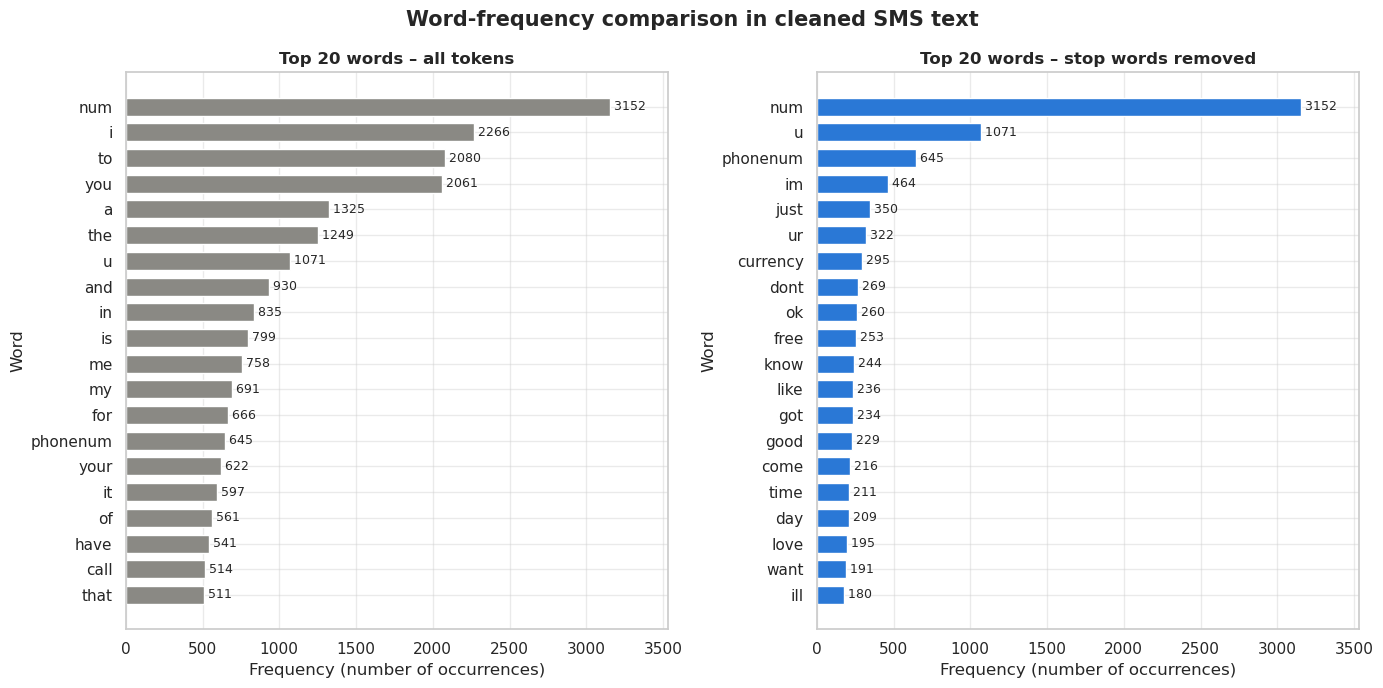

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, table, title, color in [
    (axes[0], top20_all, "Top 20 words – all tokens", "#8a8984"),
    (axes[1], top20_content, "Top 20 words – stop words removed", "#2a78d6"),
]:
    ordered = table.iloc[::-1]                        # largest bar at the top
    ax.barh(ordered["word"], ordered["frequency"], color=color, height=0.7)
    ax.set_title(title)
    ax.set_xlabel("Frequency (number of occurrences)")
    ax.set_ylabel("Word")
    for y, value in enumerate(ordered["frequency"]):
        ax.text(value, y, f" {value}", va="center", fontsize=9)
    ax.margins(x=0.12)
fig.suptitle("Word-frequency comparison in cleaned SMS text", fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_word_frequency.png")
plt.show()

## 10. Spam vs Ham comparison

In [37]:
group_stats = (df.groupby("label", observed=True)
                 .agg(messages=("message", "size"),
                      avg_char_count=("char_count", "mean"),
                      median_char_count=("char_count", "median"),
                      avg_word_count=("word_count", "mean"),
                      avg_unique_words=("unique_word_count", "mean"),
                      avg_digit_count=("digit_count", "mean"),
                      pct_with_url=("has_url", lambda s: 100 * s.mean()))
                 .round(2))
group_stats

,messages,avg_char_count,median_char_count,avg_word_count,avg_unique_words,avg_digit_count,pct_with_url
label,,,,,,,
ham,4518,70.89,53.0,14.23,13.1,0.30,0.22
spam,653,137.71,148.0,23.74,22.3,15.49,17.76


In [38]:
def top_words(frame: pd.DataFrame, n: int = 10) -> pd.DataFrame:
    # Top-n non-stop-word tokens in a subset of the data.
    counter = Counter(t for tokens in frame["tokens"] for t in tokens if t not in STOP_WORDS)
    return pd.DataFrame(counter.most_common(n), columns=["word", "frequency"])

top10_ham = top_words(df[df["label"] == "ham"])
top10_spam = top_words(df[df["label"] == "spam"])
top10_side_by_side = pd.concat([top10_ham, top10_spam], axis=1, keys=["HAM", "SPAM"])
top10_side_by_side.index = np.arange(1, 11)
top10_side_by_side

HAM                SPAM          
    word frequency      word frequency
1    num      1101       num      2051
2      u       925  phonenum       642
3     im       449  currency       271
4   just       282      free       197
5     ok       255         p       158
6   dont       252         u       146
7    got       228       txt       136
8   know       226       url       123
9   like       224        ur       119
10  good       217      stop       116

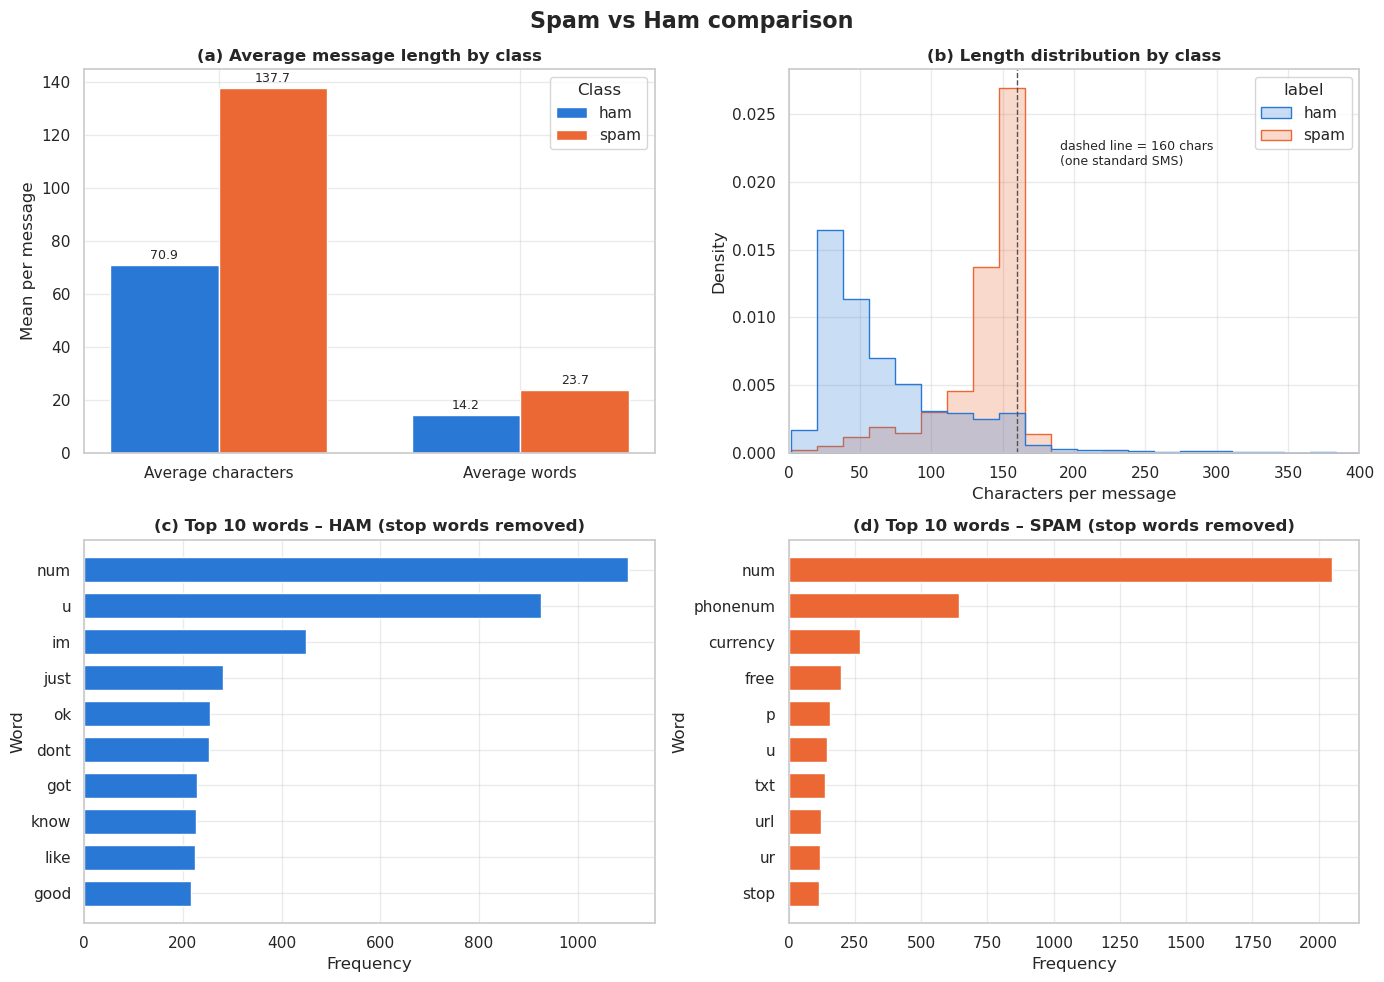

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) Average character and word count per class
metric_names = ["avg_char_count", "avg_word_count"]
x = np.arange(len(metric_names))
width = 0.36
for offset, label in [(-width / 2, "ham"), (width / 2, "spam")]:
    values = group_stats.loc[label, metric_names].values
    bars = axes[0, 0].bar(x + offset, values, width, label=label, color=CLASS_COLORS[label])
    axes[0, 0].bar_label(bars, fmt="%.1f", padding=2, fontsize=9)
axes[0, 0].set_xticks(x, ["Average characters", "Average words"])
axes[0, 0].set_ylabel("Mean per message")
axes[0, 0].set_title("(a) Average message length by class")
axes[0, 0].legend(title="Class")

# (b) Distribution of character counts per class
sns.histplot(data=df, x="char_count", hue="label", palette=CLASS_COLORS, bins=50, stat="density",
             common_norm=False, element="step", ax=axes[0, 1])
axes[0, 1].axvline(160, color="#52514e", ls="--", lw=1)
axes[0, 1].text(190, axes[0, 1].get_ylim()[1] * 0.75, "dashed line = 160 chars\n(one standard SMS)", fontsize=9)
axes[0, 1].set_xlim(0, 400)
axes[0, 1].set_xlabel("Characters per message")
axes[0, 1].set_ylabel("Density")
axes[0, 1].set_title("(b) Length distribution by class")

# (c, d) Top-10 words per class
for ax, table, label in [(axes[1, 0], top10_ham, "ham"), (axes[1, 1], top10_spam, "spam")]:
    ordered = table.iloc[::-1]
    ax.barh(ordered["word"], ordered["frequency"], color=CLASS_COLORS[label], height=0.7)
    ax.set_title(f"({'c' if label == 'ham' else 'd'}) Top 10 words – {label.upper()} (stop words removed)")
    ax.set_xlabel("Frequency")
    ax.set_ylabel("Word")

fig.suptitle("Spam vs Ham comparison", fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_spam_vs_ham_comparison.png")
plt.show()

## 11. Written insights

The evidence for every insight is computed in the next cell, so the numbers below are taken directly from the results of this notebook.

In [40]:
# Evidence used by the insights (all values computed, none typed by hand)
ham_stats, spam_stats = group_stats.loc["ham"], group_stats.loc["spam"]
spam_rate_by_bin = pd.crosstab(df["length_bin"], df["label"], normalize="index")["spam"].mul(100).round(1)
tokens_in = lambda word, label: int(sum(t == word for tokens in df.loc[df["label"] == label, "tokens"] for t in tokens))
share_with = lambda word, label: 100 * df.loc[df["label"] == label, "tokens"].apply(lambda t: word in t).mean()
stop_share = 1 - len(content_tokens) / total_tokens

evidence = {
    "dup_rows_removed": shape_before[0] - shape_after[0],
    "spam_pct_clean": round(100 * df["label_num"].mean(), 2),
    "ham_avg_chars": ham_stats["avg_char_count"], "spam_avg_chars": spam_stats["avg_char_count"],
    "ham_avg_words": ham_stats["avg_word_count"], "spam_avg_words": spam_stats["avg_word_count"],
    "ham_avg_digits": ham_stats["avg_digit_count"], "spam_avg_digits": spam_stats["avg_digit_count"],
    "spam_pct_by_length_bin": spam_rate_by_bin.to_dict(),
    "pct_spam_with_phonenum": round(share_with("phonenum", "spam"), 1),
    "pct_ham_with_phonenum": round(share_with("phonenum", "ham"), 1),
    "pct_spam_with_free": round(share_with("free", "spam"), 1),
    "pct_ham_with_free": round(share_with("free", "ham"), 1),
    "stop_word_share_of_tokens_pct": round(100 * stop_share, 1),
    "stop_words_in_top20": int(top20_all["is_stop_word"].sum()),
    "corr_digit_label": round(corr_matrix.loc["digit_count", "label_num"], 3),
    "corr_char_label": round(corr_matrix.loc["char_count", "label_num"], 3),
    "corr_char_word": round(corr_matrix.loc["char_count", "word_count"], 3),
    "top10_ham": top10_ham["word"].tolist(),
    "top10_spam": top10_spam["word"].tolist(),
}
for key, value in evidence.items():
    print(f"{key:32s}: {value}")

dup_rows_removed                : 403
spam_pct_clean                  : 12.63
ham_avg_chars                   : 70.89
spam_avg_chars                  : 137.71
ham_avg_words                   : 14.23
spam_avg_words                  : 23.74
ham_avg_digits                  : 0.3
spam_avg_digits                 : 15.49
spam_pct_by_length_bin          : {'short (<=40)': 0.6, 'medium (41-100)': 3.2, 'long (101-160)': 39.6, 'very long (>160)': 21.6}
pct_spam_with_phonenum          : 75.8
pct_ham_with_phonenum           : 0.1
pct_spam_with_free              : 23.0
pct_ham_with_free               : 1.2
stop_word_share_of_tokens_pct   : 43.5
stop_words_in_top20             : 17
corr_digit_label                : 0.837
corr_char_label                 : 0.381
corr_char_word                  : 0.974
top10_ham                       : ['num', 'u', 'im', 'just', 'ok', 'dont', 'got', 'know', 'like', 'good']
top10_spam                      : ['num', 'phonenum', 'currency', 'free', 'p', 'u', 'txt', 'url',

### Insights (observation → evidence → interpretation)

**Insight 1 – Spam messages are about twice as long as ham and cluster just below the 160-character SMS limit.**
* *Observation:* spam is consistently longer than ham.
* *Evidence:* average length is **137.71 characters / 23.74 words for spam** vs **70.89 characters / 14.23 words for ham**; the median spam length is 148 characters. The spam share is only **0.6%** among messages of ≤ 40 characters but **39.6%** among messages of 101–160 characters (Section 10 table, evidence cell above).
* *Interpretation:* spammers pay per message, so they fill one 160-character SMS segment with as much advertising as possible, while personal messages are short replies. Message length is therefore a useful (but not sufficient) spam signal.

**Insight 2 – Numbers are the single strongest spam indicator.**
* *Observation:* spam contains far more digits, especially long phone numbers and short codes.
* *Evidence:* **15.49 digits per spam message vs 0.30 per ham message**; `digit_count` has the highest correlation with the label (**r = 0.837**); the `phonenum` token (≥ 5 consecutive digits) appears in **75.8% of spam** but only **0.1% of ham**.
* *Interpretation:* spam is a call to action (“call 0906…”, “text WIN to 87121”). This justified *replacing* numbers with `num` / `phonenum` tokens during cleaning instead of deleting them – the value is irrelevant, but its presence is highly informative.

**Insight 3 – Stop words dominate raw SMS text, and SMS shorthand survives stop-word removal.**
* *Observation:* the raw frequency ranking is mostly function words.
* *Evidence:* **17 of the top-20 words** are stop words, and stop words make up **43.5%** of all 81,818 tokens. After removal, the top words include SMS shorthand such as `u` (1,071), `im`, `ur` and `dont`.
* *Interpretation:* standard stop-word lists remove grammatical noise but are designed for formal English; SMS language needs domain-specific handling (e.g. `u` = *you*). For classification we did **not** remove stop words because words such as *your* or *call* carry spam signal in context.

**Insight 4 – Spam vocabulary is promotional and transactional, ham vocabulary is conversational.**
* *Observation:* the top-10 words of the two groups barely overlap.
* *Evidence:* spam top-10: `num, phonenum, currency, free, p, u, txt, url, ur, stop`; ham top-10: `num, u, im, just, ok, dont, got, know, like, good`. The word *free* appears in **23.0% of spam** vs **1.2% of ham**.
* *Interpretation:* spam is about prices (`currency`, `p` = pence), offers (*free*), and instructions (*txt*, *stop* to unsubscribe), while ham is about everyday coordination. This strong lexical separation explains why a simple TF-IDF model achieves high accuracy in Section 12.

**Insight 5 – Duplicate messages are disproportionately spam, and removing them changes the class balance.**
* *Observation:* the raw file contains many repeated messages.
* *Evidence:* **403 exact duplicate rows** were removed (309 ham, 94 spam). That is 94 of 747 spam rows (12.6%) vs 309 of 4,827 ham rows (6.4%). The spam share fell from 13.40% to **12.63%** after cleaning.
* *Interpretation:* spam is sent in bulk, so the same text is collected many times. Without deduplication, identical messages would appear in both training and test sets (data leakage) and the evaluation would be over-optimistic.

**Insight 6 – The size features are redundant with one another.**
* *Observation:* character count, word count and unique word count move together.
* *Evidence:* `char_count` vs `word_count` **r = 0.974**, and `word_count` vs `unique_word_count` r = 0.981, while `avg_word_length` is nearly uncorrelated with them (|r| < 0.09).
* *Interpretation:* these three features measure the same property (message size). A model would gain little from using all three; one of them plus `digit_count` captures most of the numeric signal.

## 12. Supervised text classification

* **Target:** `label_num` (spam = 1 is the *positive* class).
* **Input:** `cleaned_text`.
* **Split:** 80% train / 20% test, **stratified** by label so both sets keep the ~87/13 class ratio.
* **Features:** TF-IDF (unigrams + bigrams, `min_df=2`, `sublinear_tf=True`).
* **Leakage prevention:** TF-IDF is placed **inside an sklearn `Pipeline`**, so the vocabulary and IDF weights are learned from the
  **training set only** (`fit` is never called on test data). Duplicates were already removed, so identical messages cannot sit on both sides of the split.
* **Models:** Multinomial Naive Bayes (required classifier) and Logistic Regression (second classifier → bonus comparison).

In [41]:
X = df["cleaned_text"]
y = df["label_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "rows": [len(y_train), len(y_test)],
    "spam %": [round(100 * y_train.mean(), 2), round(100 * y_test.mean(), 2)],
}, index=["train", "test"])
split_summary

,rows,spam %
train,4136,12.62
test,1035,12.66


In [42]:
def make_tfidf() -> TfidfVectorizer:
    # Fresh TF-IDF vectorizer (same settings for every model -> fair comparison).
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", make_tfidf()),
        ("classifier", MultinomialNB(alpha=0.1)),
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", make_tfidf()),
        # class_weight='balanced' compensates for the 87/13 class imbalance
        ("classifier", LogisticRegression(C=10, class_weight="balanced", max_iter=2000,
                                          random_state=RANDOM_STATE)),
    ]),
}

# 5-fold stratified cross-validation on the TRAINING set only (the pipeline refits TF-IDF in every fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipeline in models.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv,
                            scoring=["accuracy", "precision", "recall", "f1"])
    cv_rows.append({"model": name, **{f"cv_{m}": f"{scores['test_' + m].mean():.4f} ± {scores['test_' + m].std():.4f}"
                                       for m in ["accuracy", "precision", "recall", "f1"]}})
cv_results = pd.DataFrame(cv_rows).set_index("model")
cv_results

,cv_accuracy,cv_precision,cv_recall,cv_f1
model,,,,
Multinomial Naive Bayes,0.9879 ± 0.0050,0.9856 ± 0.0083,0.9175 ± 0.0389,0.9499 ± 0.0221
Logistic Regression,0.9891 ± 0.0039,0.9636 ± 0.0216,0.9501 ± 0.0239,0.9565 ± 0.0159


In [43]:
# Fit on the full training set and evaluate ONCE on the held-out test set
test_rows, predictions, reports = [], {}, {}
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    predictions[name] = y_pred
    test_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision (spam)": precision_score(y_test, y_pred, zero_division=0),
        "recall (spam)": recall_score(y_test, y_pred, zero_division=0),
        "f1 (spam)": f1_score(y_test, y_pred, zero_division=0),
        "f1 (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
    })
    reports[name] = classification_report(y_test, y_pred, target_names=["ham", "spam"], digits=4, zero_division=0)

test_results = pd.DataFrame(test_rows).set_index("model").round(4)
print("Vocabulary size learned from TRAINING data only:",
      {name: len(p.named_steps["tfidf"].vocabulary_) for name, p in models.items()})
test_results

Vocabulary size learned from TRAINING data only: {'Multinomial Naive Bayes': 10022, 'Logistic Regression': 10022}


,accuracy,precision (spam),recall (spam),f1 (spam),f1 (macro)
model,,,,,
Multinomial Naive Bayes,0.9884,0.9685,0.9389,0.9535,0.9734
Logistic Regression,0.9932,0.9844,0.9618,0.9730,0.9846


In [44]:
for name, report in reports.items():
    print(f"=== {name} ===")
    print(report)

=== Multinomial Naive Bayes ===
              precision    recall  f1-score   support

         ham     0.9912    0.9956    0.9934       904
        spam     0.9685    0.9389    0.9535       131

    accuracy                         0.9884      1035
   macro avg     0.9798    0.9673    0.9734      1035
weighted avg     0.9883    0.9884    0.9883      1035

=== Logistic Regression ===
              precision    recall  f1-score   support

         ham     0.9945    0.9978    0.9961       904
        spam     0.9844    0.9618    0.9730       131

    accuracy                         0.9932      1035
   macro avg     0.9894    0.9798    0.9846      1035
weighted avg     0.9932    0.9932    0.9932      1035



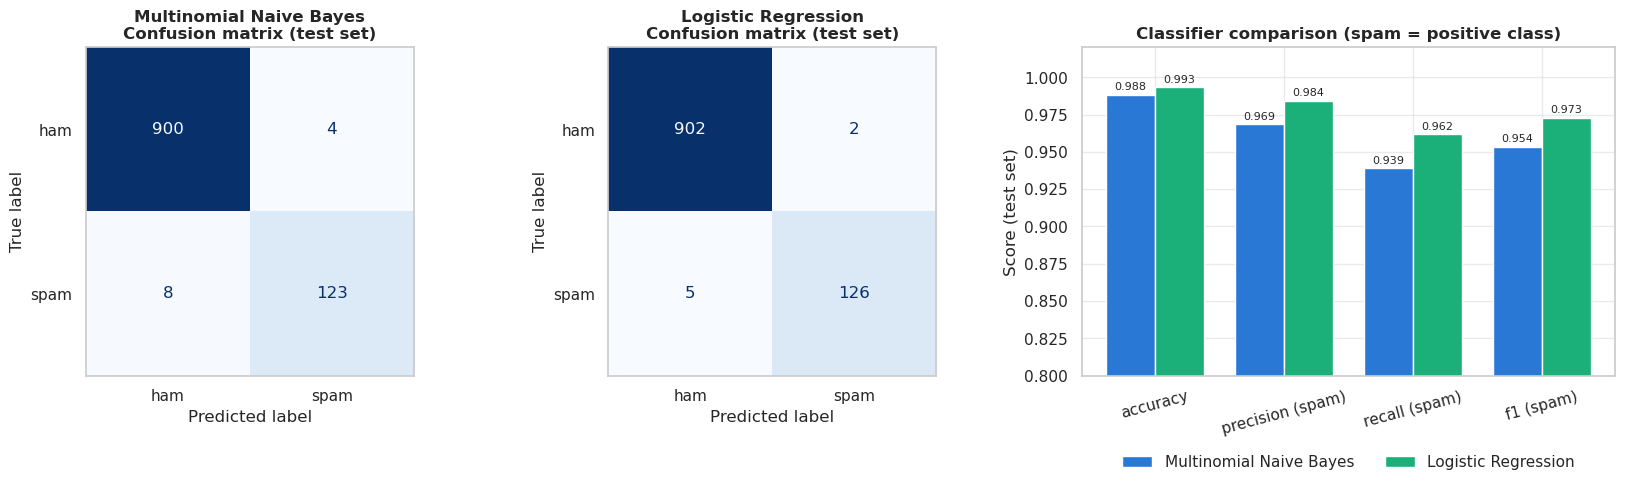

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1, 1.25]})

# Confusion matrices (raw counts) for both classifiers
for ax, (name, y_pred) in zip(axes[:2], predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}\nConfusion matrix (test set)")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.grid(False)

# Metric comparison
metric_cols = ["accuracy", "precision (spam)", "recall (spam)", "f1 (spam)"]
plot_data = test_results[metric_cols].T
x = np.arange(len(metric_cols))
width = 0.38
for offset, (name, color) in zip([-width / 2, width / 2],
                                 [("Multinomial Naive Bayes", "#2a78d6"), ("Logistic Regression", "#1baf7a")]):
    bars = axes[2].bar(x + offset, plot_data[name], width, label=name, color=color)
    axes[2].bar_label(bars, fmt="%.3f", padding=2, fontsize=8)
axes[2].set_xticks(x, metric_cols, rotation=15)
axes[2].set_ylim(0.8, 1.02)
axes[2].set_ylabel("Score (test set)")
axes[2].set_title("Classifier comparison (spam = positive class)")
axes[2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)

fig.tight_layout()
fig.savefig(FIG_DIR / "04_confusion_matrices_model_comparison.png")
plt.show()

In [46]:
# Most informative terms of the Logistic Regression model (positive weight -> pushes towards spam)
lr_pipeline = models["Logistic Regression"]
feature_names = lr_pipeline.named_steps["tfidf"].get_feature_names_out()
coefficients = lr_pipeline.named_steps["classifier"].coef_[0]
order = np.argsort(coefficients)
informative_terms = pd.DataFrame({
    "strongest HAM terms": feature_names[order[:15]],
    "strongest SPAM terms": feature_names[order[::-1][:15]],
})
informative_terms

,strongest HAM terms,strongest SPAM terms
0,my,phonenum
1,me,url
2,at,num
3,ok,text
4,its,free
5,that,reply
6,got,num num
7,then,currency
8,hey,txt
9,im,to phonenum


In [47]:
# Error analysis: which test messages does each model get wrong?
error_frames = []
for name, y_pred in predictions.items():
    wrong = X_test.index[(y_pred != y_test.values)]
    error_frames.append(pd.DataFrame({
        "model": name,
        "true": df.loc[wrong, "label"].astype(str),
        "message": df.loc[wrong, "message"],
    }))
errors = pd.concat(error_frames)
print("Misclassified test messages per model:")
print(errors.groupby(["model", "true"]).size().rename("count").to_string())
errors.head(10)

Misclassified test messages per model:
model                    true
Logistic Regression      ham     2
                         spam    5
Multinomial Naive Bayes  ham     4
                         spam    8


,model,true,message
4499,Multinomial Naive Bayes,spam,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo
2642,Multinomial Naive Bayes,spam,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-C...
4538,Multinomial Naive Bayes,ham,Nokia phone is lovly..
3332,Multinomial Naive Bayes,spam,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & S..."
1813,Multinomial Naive Bayes,spam,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!
2303,Multinomial Naive Bayes,spam,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...
3949,Multinomial Naive Bayes,spam,Missed call alert. These numbers called but left no message. 07008009200
4416,Multinomial Naive Bayes,ham,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to &...
3890,Multinomial Naive Bayes,spam,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Da..."
4419,Multinomial Naive Bayes,ham,K:)eng rocking in ashes:)


In [48]:
# Pick the best model by F1 on the spam class (the metric that balances precision and recall for the minority class)
best_model_name = test_results["f1 (spam)"].idxmax()
print("Best model on test F1 (spam):", best_model_name)

# Write model_metrics.txt
with open(OUTPUT_DIR / "model_metrics.txt", "w", encoding="utf-8") as f:
    f.write("CSCI461 Assignment 1 - Supervised Text Classification Results\n")
    f.write("Dataset: UCI SMS Spam Collection (after cleaning: {} messages)\n".format(len(df)))
    f.write("=" * 72 + "\n\n")
    f.write("Setup\n-----\n")
    f.write("Target            : label_num (ham = 0, spam = 1; spam is the positive class)\n")
    f.write("Input text        : cleaned_text\n")
    f.write(f"Train/test split  : 80/20, stratified, random_state={RANDOM_STATE}\n")
    f.write(f"Train rows        : {len(y_train)} (spam {100 * y_train.mean():.2f}%)\n")
    f.write(f"Test rows         : {len(y_test)} (spam {100 * y_test.mean():.2f}%)\n")
    f.write("Features          : TF-IDF (ngram_range=(1,2), min_df=2, sublinear_tf=True)\n")
    f.write("Leakage control   : TF-IDF fitted inside sklearn Pipeline on training data only\n\n")
    f.write("5-fold stratified cross-validation on the training set (mean ± std)\n")
    f.write("-" * 66 + "\n")
    f.write(cv_results.to_string() + "\n\n")
    f.write("Held-out test-set results\n-------------------------\n")
    f.write(test_results.to_string() + "\n\n")
    for name, y_pred in predictions.items():
        cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
        f.write(f"=== {name} ===\n")
        f.write(reports[name] + "\n")
        f.write("Confusion matrix (rows = true, columns = predicted) [ham, spam]:\n")
        f.write(f"            pred_ham  pred_spam\n")
        f.write(f"true_ham    {cm[0, 0]:8d}  {cm[0, 1]:9d}\n")
        f.write(f"true_spam   {cm[1, 0]:8d}  {cm[1, 1]:9d}\n\n")
    f.write(f"Best model by test F1 (spam): {best_model_name}\n\n")
    f.write("Limitations\n-----------\n")
    f.write("- Class imbalance (~12% spam): accuracy alone is misleading; precision/recall/F1 on spam are reported.\n")
    f.write("- Bag-of-words TF-IDF ignores word order and context; obfuscated spam (e.g. 'fr33') can evade it.\n")
    f.write("- The corpus is small and dated (UK/Singapore SMS, ~2000s-2012); performance on modern SMS may differ.\n")
    f.write("- A single test split of ~1000 messages (~130 spam): one error changes spam recall by ~0.8 points.\n")

print((OUTPUT_DIR / "model_metrics.txt").read_text(encoding="utf-8"))

Best model on test F1 (spam): Logistic Regression
CSCI461 Assignment 1 - Supervised Text Classification Results
Dataset: UCI SMS Spam Collection (after cleaning: 5171 messages)

Setup
-----
Target            : label_num (ham = 0, spam = 1; spam is the positive class)
Input text        : cleaned_text
Train/test split  : 80/20, stratified, random_state=42
Train rows        : 4136 (spam 12.62%)
Test rows         : 1035 (spam 12.66%)
Features          : TF-IDF (ngram_range=(1,2), min_df=2, sublinear_tf=True)
Leakage control   : TF-IDF fitted inside sklearn Pipeline on training data only

5-fold stratified cross-validation on the training set (mean ± std)
------------------------------------------------------------------
                             cv_accuracy     cv_precision        cv_recall            cv_f1
model                                                                                      
Multinomial Naive Bayes  0.9879 ± 0.0050  0.9856 ± 0.0083  0.9175 ± 0.0389  0.9499 ± 0.022

### Interpretation of the classification results

*(Numbers refer to the test-set table, classification reports and confusion matrices above.)*

* **Both models perform strongly**, well above the trivial baseline of always predicting *ham* (87.3% accuracy, 0% spam recall).
* **Logistic Regression is the better classifier on this split:** accuracy **0.9932 vs 0.9884**, spam precision **0.9844 vs 0.9685**, spam recall **0.9618 vs 0.9389**, spam F1 **0.9730 vs 0.9535**.
  In the confusion matrices, LR makes **2 false positives and 5 false negatives**, Naive Bayes **4 false positives and 8 false negatives** (out of 904 ham / 131 spam test messages).
* **The difference is modest.** In 5-fold cross-validation on the training set, the mean spam F1 scores of the two models (≈ 0.95 and ≈ 0.96) are within one standard deviation of each other. Naive Bayes reaches higher CV *precision*, while Logistic Regression (with `class_weight="balanced"`) trades a little precision for higher *recall*.
* **Why precision matters here:** a false positive means a real personal message is hidden in a spam folder, which is usually worse for the user than letting one spam through. Both models keep false positives very low.
* **What the model learned:** the strongest spam terms of the Logistic Regression model are `phonenum`, `url`, `num`, `text`, `free`, `reply`, `currency` and `call phonenum`; the strongest ham terms are personal words such as `my`, `me`, `ok`, `got`, `home`, `later`. This matches the text-analysis insights.
* **Bonus – model extension:** two supervised classifiers are compared on the same leakage-free pipeline, the TF-IDF uses **word bigrams** (`ngram_range=(1, 2)`, e.g. *call phonenum*), and model selection is backed by **5-fold stratified cross-validation**.

**Limitations**
1. **Class imbalance:** only ~131 spam messages are in the test set, so a single misclassified spam message changes spam recall by ~0.8 percentage points; scores have noticeable uncertainty.
2. **Bag-of-words:** TF-IDF ignores word order and meaning. The misclassified spam above includes messages with no phone number and conversational wording (e.g. a sale announcement for tickets), and obfuscated text (e.g. `fr33`, unusual URLs) can evade the model.
3. **Dataset age and origin:** the messages are from UK and Singapore SMS around 2000-2012. Modern spam (links to phishing sites, delivery scams, messaging apps) looks different, so performance would likely drop without retraining.
4. **No hyper-parameter search:** settings (`alpha=0.1`, `C=10`, `min_df=2`) were chosen once and not tuned systematically.

## 13. K-Means clustering (unsupervised)

**Representation.** TF-IDF on `cleaned_text` (stop words removed, `min_df=3`) gives a sparse, very high-dimensional matrix. K-Means uses Euclidean
distance, which behaves poorly in such spaces, so we apply **TruncatedSVD** (Latent Semantic Analysis, 100 components) followed by
**L2 normalisation** – the standard LSA pipeline for clustering text. The labels are **not** used to build the clusters; they are only used
afterwards for comparison. (Because clustering does not train a predictor that is evaluated on held-out data, fitting TF-IDF on all messages is not leakage here.)

**Choosing k.** We run K-Means for k = 2 … 10 and record the **inertia** (within-cluster sum of squares, elbow method) and the
**silhouette score** (cohesion vs separation, range −1 … 1). k is then chosen from this experiment rather than fixed in advance.

In [49]:
cluster_tfidf = TfidfVectorizer(stop_words="english", min_df=3, sublinear_tf=True)
X_tfidf_all = cluster_tfidf.fit_transform(df["cleaned_text"])

svd = TruncatedSVD(n_components=100, random_state=RANDOM_STATE)
lsa = make_pipeline(svd, Normalizer(copy=False))
X_lsa = lsa.fit_transform(X_tfidf_all)

print("TF-IDF matrix shape:", X_tfidf_all.shape)
print("LSA matrix shape   :", X_lsa.shape)
print(f"Variance explained by 100 SVD components: {svd.explained_variance_ratio_.sum():.1%}")

TF-IDF matrix shape: (5171, 2201)
LSA matrix shape   : (5171, 100)
Variance explained by 100 SVD components: 30.7%


In [50]:
k_values = range(2, 11)
k_rows = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    cluster_ids_k = km.fit_predict(X_lsa)
    k_rows.append({
        "k": k,
        "inertia": km.inertia_,
        # Silhouette on all ~5k points is affordable (O(n^2) distances, a few seconds)
        "silhouette": silhouette_score(X_lsa, cluster_ids_k, random_state=RANDOM_STATE),
        "smallest_cluster": np.bincount(cluster_ids_k).min(),
    })
k_selection = pd.DataFrame(k_rows).set_index("k").round(4)
k_selection

,inertia,silhouette,smallest_cluster
k,,,
2,4678.1881,0.0337,1036
3,4590.5501,0.0376,400
4,4526.1392,0.0402,273
5,4458.2709,0.0471,235
6,4406.0844,0.0506,231
7,4357.8213,0.0526,222
8,4293.8445,0.0565,197
9,4249.2719,0.0605,176
10,4210.0295,0.0491,221


Chosen k = 9 (silhouette = 0.0605)


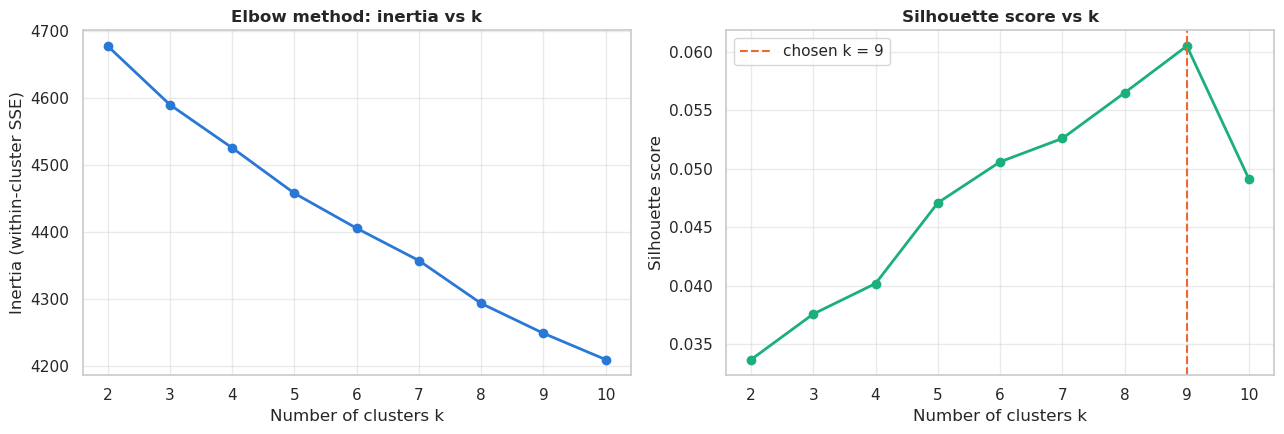

In [51]:
# Selection rule: highest silhouette score, but a cluster must contain at least 1% of the messages
# (otherwise a tiny group of near-identical texts can win the silhouette without describing the data).
min_cluster_size = int(0.01 * len(df))
eligible = k_selection[k_selection["smallest_cluster"] >= min_cluster_size]
best_k = int(eligible["silhouette"].idxmax())
print(f"Chosen k = {best_k} (silhouette = {k_selection.loc[best_k, 'silhouette']:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_selection.index, k_selection["inertia"], marker="o", color="#2a78d6", lw=2)
axes[0].set_title("Elbow method: inertia vs k")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[1].plot(k_selection.index, k_selection["silhouette"], marker="o", color="#1baf7a", lw=2)
axes[1].axvline(best_k, color="#eb6834", ls="--", lw=1.5, label=f"chosen k = {best_k}")
axes[1].set_title("Silhouette score vs k")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette score")
axes[1].legend()
for ax in axes:
    ax.set_xticks(list(k_values))
fig.tight_layout()
fig.savefig(FIG_DIR / "05_kmeans_k_selection.png")
plt.show()

In [52]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
df["cluster"] = kmeans.fit_predict(X_lsa)
final_silhouette = silhouette_score(X_lsa, df["cluster"], random_state=RANDOM_STATE)

cluster_sizes = df["cluster"].value_counts().sort_index().rename("messages")
print(f"Final model: k = {best_k}, silhouette = {final_silhouette:.4f}\n")
print(cluster_sizes.to_frame().assign(percent=lambda t: (100 * t["messages"] / len(df)).round(2)))

Final model: k = 9, silhouette = 0.0605

         messages  percent
cluster                   
0             283     5.47
1             333     6.44
2             176     3.40
3             310     5.99
4             199     3.85
5             300     5.80
6             803    15.53
7            2375    45.93
8             392     7.58


In [53]:
# Top terms per cluster: map centroids from LSA space back to TF-IDF term space
centroids_terms = svd.inverse_transform(kmeans.cluster_centers_)
terms = cluster_tfidf.get_feature_names_out()
top_terms = {c: terms[np.argsort(centroids_terms[c])[::-1][:12]].tolist() for c in range(best_k)}

# Compare clusters with the known labels
cluster_vs_label = pd.crosstab(df["cluster"], df["label"])
cluster_vs_label["spam %"] = (100 * cluster_vs_label["spam"] / cluster_vs_label.sum(axis=1)).round(1)

cluster_profile = cluster_vs_label.copy()
cluster_profile["avg_chars"] = df.groupby("cluster")["char_count"].mean().round(1)
cluster_profile["top terms"] = [", ".join(top_terms[c]) for c in cluster_profile.index]
cluster_profile

label,ham,spam,spam %,avg_chars,top terms
cluster,,,,,
0,283,0,0.0,66.0,"lor, wat, num, dun, wan, thk, say, cos, dunno, ask, lar, liao"
1,324,9,2.7,83.8,"im, num, home, going, gonna, want, just, sorry, really, ill, ready, week"
2,172,4,2.3,91.5,"like, num, feel, dat, think, just, im, dont, sounds, ill, know, dun"
3,308,2,0.6,57.6,"ok, come, num, time, ill, ur, tomorrow, home, said, ask, want, going"
4,195,4,2.0,95.2,"good, morning, day, hope, night, love, im, num, happy, sleep, time, evening"
5,298,2,0.7,97.6,"dont, know, let, want, just, think, need, num, worry, ill, sure, pls"
6,236,567,70.6,124.0,"num, phonenum, currency, free, txt, url, ur, stop, mobile, claim, text, reply"
7,2319,56,2.4,64.8,"ur, love, life, time, need, hey, today, think, day, did, going, great"
8,383,9,2.3,71.7,"just, got, da, num, ive, sorry, sent, money, want, send, yeah, yo"


In [54]:
# Representative messages = those closest to each centroid
distances = kmeans.transform(X_lsa)
for c in range(best_k):
    closest = np.argsort(distances[:, c])[:3]
    print(f"--- Cluster {c} (n={cluster_sizes[c]}, spam {cluster_vs_label.loc[c, 'spam %']}%) ---")
    for i in closest:
        print(f"  [{df.loc[i, 'label']}] {df.loc[i, 'message'][:110]}")

--- Cluster 0 (n=283, spam 0.0%) ---
  [ham] We have all rounder:)so not required:)
  [ham] He is a womdarfull actor
  [ham] Host-based IDPS for linux systems.
--- Cluster 1 (n=333, spam 2.7%) ---
  [ham] I'm not. She lip synced with shangela.
  [ham] I'm done. C ü there.
  [ham] I'm done...
--- Cluster 2 (n=176, spam 2.3%) ---
  [ham] You'd like that wouldn't you? Jerk!
  [ham] You do what all you like
  [ham] will you like to be spoiled? :)
--- Cluster 3 (n=310, spam 0.6%) ---
  [ham]  &lt;#&gt;  in mca. But not conform.
  [ham] U can call me now...
  [ham] That is wondar full flim.
--- Cluster 4 (n=199, spam 2.0%) ---
  [ham] […] anyway, many good evenings to u! s
  [ham] Good. No swimsuit allowed :)
  [ham] Good evening! How are you?
--- Cluster 5 (n=300, spam 0.7%) ---
  [ham] Those ducking chinchillas
  [ham] Raviyog Peripherals bhayandar east
  [ham] Found it, ENC  &lt;#&gt; , where you at?
--- Cluster 6 (n=803, spam 70.6%) ---
  [spam] 08714712388 between 10am-7pm Cost 10p
  [s

Cluster purity w.r.t. labels : 0.9377  (baseline = majority class share 0.8737)
Adjusted Rand Index          : 0.1146
Homogeneity                  : 0.5418


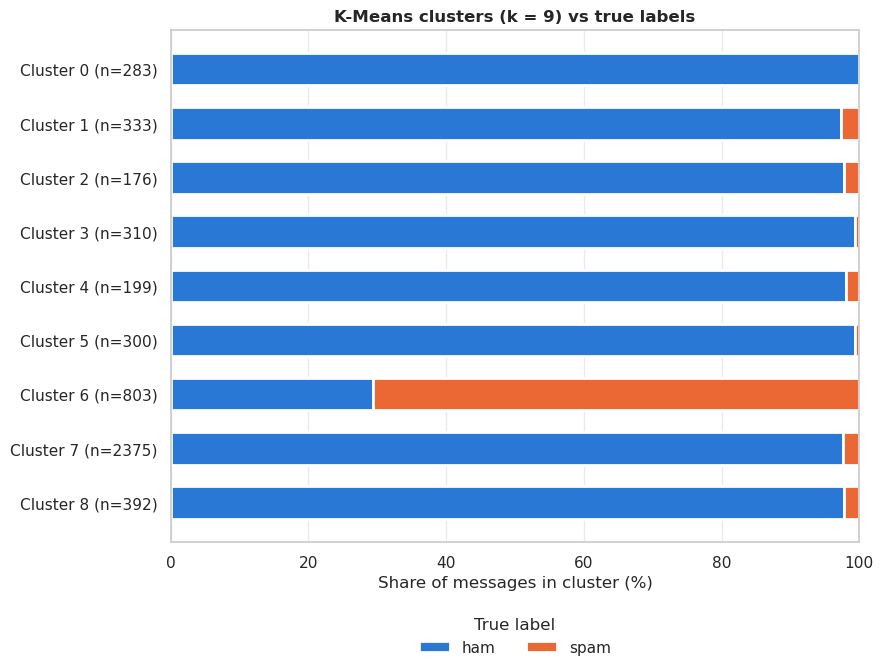

In [55]:
# Agreement between clusters and labels (permutation-invariant measures)
from sklearn.metrics import adjusted_rand_score, homogeneity_score

purity = cluster_vs_label[["ham", "spam"]].max(axis=1).sum() / len(df)
ari = adjusted_rand_score(df["label_num"], df["cluster"])
homogeneity = homogeneity_score(df["label_num"], df["cluster"])
print(f"Cluster purity w.r.t. labels : {purity:.4f}  (baseline = majority class share {1 - df['label_num'].mean():.4f})")
print(f"Adjusted Rand Index          : {ari:.4f}")
print(f"Homogeneity                  : {homogeneity:.4f}")

fig, ax = plt.subplots(figsize=(9, max(3.5, 0.6 * best_k + 1.5)))
shares = pd.crosstab(df["cluster"], df["label"], normalize="index").mul(100)
left = np.zeros(len(shares))
for label in ["ham", "spam"]:
    ax.barh([f"Cluster {c} (n={cluster_sizes[c]})" for c in shares.index], shares[label], left=left,
            color=CLASS_COLORS[label], label=label, height=0.6, edgecolor="white", linewidth=2)
    left += shares[label].values
ax.set_xlabel("Share of messages in cluster (%)")
ax.set_title(f"K-Means clusters (k = {best_k}) vs true labels")
ax.legend(title="True label", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(FIG_DIR / "07_clusters_vs_labels.png")
plt.show()

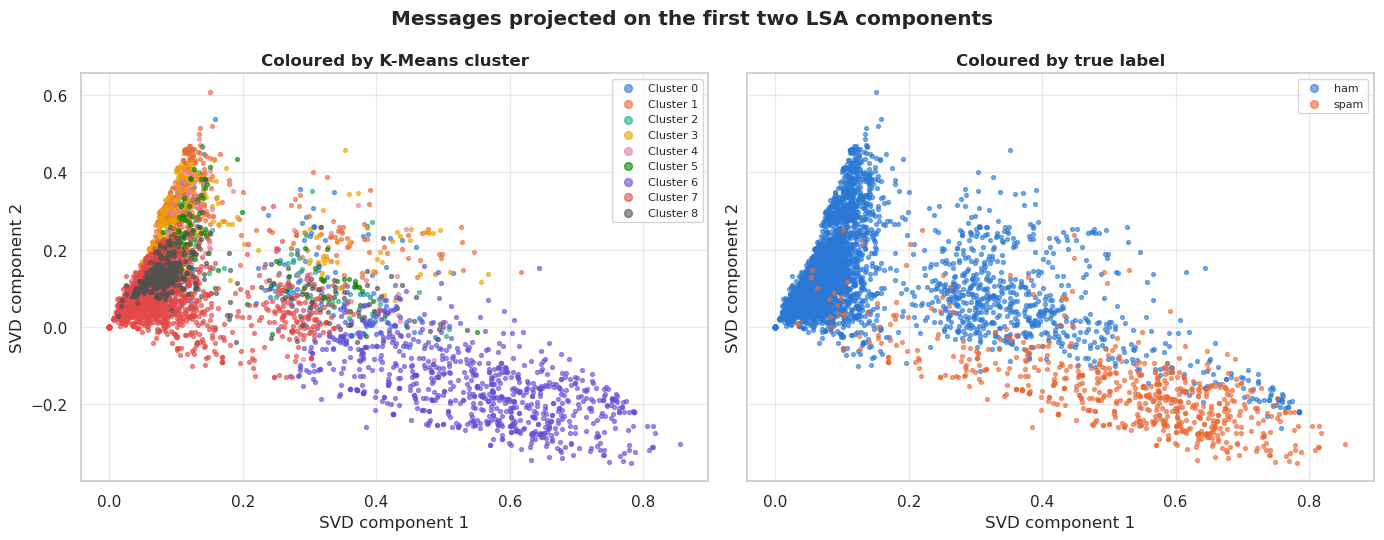

In [56]:
# 2-D view of the clusters (first two SVD components), coloured by cluster
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
cluster_palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948",
                   "#52514e", "#8a8984"]
for c in range(best_k):
    mask = df["cluster"] == c
    axes[0].scatter(X_lsa[mask, 0], X_lsa[mask, 1], s=8, alpha=0.6, color=cluster_palette[c], label=f"Cluster {c}")
for label in ["ham", "spam"]:
    mask = (df["label"] == label).values
    axes[1].scatter(X_lsa[mask, 0], X_lsa[mask, 1], s=8, alpha=0.6, color=CLASS_COLORS[label], label=label)
axes[0].set_title("Coloured by K-Means cluster")
axes[1].set_title("Coloured by true label")
for ax in axes:
    ax.set_xlabel("SVD component 1")
    ax.set_ylabel("SVD component 2")
    ax.legend(markerscale=2, fontsize=8)
fig.suptitle("Messages projected on the first two LSA components", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "08_cluster_projection.png")
plt.show()

In [57]:
def describe_cluster(c: int) -> str:
    # Rule-based one-line description derived from the cluster's measured spam share and top terms.
    spam_pct = cluster_vs_label.loc[c, "spam %"]
    overall = 100 * df["label_num"].mean()
    if spam_pct >= 50:
        kind = "spam-dominated (promotional / prize / call-to-action messages)"
    elif spam_pct >= 2 * overall:
        kind = "mixed, spam over-represented"
    elif spam_pct <= overall / 2:
        kind = "almost purely ham (personal conversation)"
    else:
        kind = "mostly ham, spam near the overall rate"
    return f"{kind}; spam share {spam_pct:.1f}% vs {overall:.1f}% overall; key terms: {', '.join(top_terms[c][:6])}"


with open(OUTPUT_DIR / "cluster_summary.txt", "w", encoding="utf-8") as f:
    f.write("CSCI461 Assignment 1 - K-Means Clustering Summary\n")
    f.write("=" * 60 + "\n\n")
    f.write("Representation : TF-IDF (english stop words removed, min_df=3, sublinear_tf)\n")
    f.write(f"                 -> TruncatedSVD(100 components, {svd.explained_variance_ratio_.sum():.1%} variance) -> L2 normalisation\n")
    f.write("Algorithm      : KMeans(n_init=10, random_state=42)\n")
    f.write("k selection    : k = 2..10 evaluated with inertia (elbow) and silhouette score;\n")
    f.write("                 chosen k = highest silhouette with every cluster >= 1% of messages\n\n")
    f.write("k-selection experiment\n" + k_selection.to_string() + "\n\n")
    f.write(f"Chosen k                 : {best_k}\n")
    f.write(f"Silhouette score (final) : {final_silhouette:.4f}\n")
    f.write(f"Inertia (final)          : {kmeans.inertia_:.2f}\n\n")
    f.write("Cluster sizes and label composition\n")
    f.write(cluster_vs_label.to_string() + "\n\n")
    f.write("Top terms and interpretation per cluster\n")
    for c in range(best_k):
        f.write(f"- Cluster {c} (n={cluster_sizes[c]}): {describe_cluster(c)}\n")
        f.write(f"    top terms: {', '.join(top_terms[c])}\n")
    f.write("\nComparison with known labels\n")
    f.write(f"Purity = {purity:.4f} (majority-class baseline {1 - df['label_num'].mean():.4f}), "
            f"ARI = {ari:.4f}, homogeneity = {homogeneity:.4f}\n")
    f.write("Cluster IDs are arbitrary integers assigned by K-Means; they do not correspond to the label codes\n"
            "(ham=0, spam=1). Clusters group messages by vocabulary/topic, not by the spam/ham definition.\n")
    f.write("A low silhouette is typical for short, sparse texts: SMS messages overlap heavily in vocabulary.\n")

print((OUTPUT_DIR / "cluster_summary.txt").read_text(encoding="utf-8"))

CSCI461 Assignment 1 - K-Means Clustering Summary

Representation : TF-IDF (english stop words removed, min_df=3, sublinear_tf)
                 -> TruncatedSVD(100 components, 30.7% variance) -> L2 normalisation
Algorithm      : KMeans(n_init=10, random_state=42)
k selection    : k = 2..10 evaluated with inertia (elbow) and silhouette score;
                 chosen k = highest silhouette with every cluster >= 1% of messages

k-selection experiment
      inertia  silhouette  smallest_cluster
k                                          
2   4678.1881      0.0337              1036
3   4590.5501      0.0376               400
4   4526.1392      0.0402               273
5   4458.2709      0.0471               235
6   4406.0844      0.0506               231
7   4357.8213      0.0526               222
8   4293.8445      0.0565               197
9   4249.2719      0.0605               176
10  4210.0295      0.0491               221

Chosen k                 : 9
Silhouette score (final) : 0.0605

### Interpretation of the K-Means results

**Choice of k.** Silhouette scores are low for every k (≈ 0.03–0.06), which is normal for short, sparse texts that share much vocabulary. The silhouette increases up to **k = 9** and drops at k = 10, while the inertia curve decreases smoothly without a sharp elbow. We therefore chose **k = 9**, the silhouette maximum in the tested range. Every cluster of this solution contains more than 1% of the messages. k was not fixed to 3 in advance.

**What each cluster represents** (from the top terms, the representative messages and the label composition above):

| Cluster | Size | Spam % | Top terms (excerpt) | Interpretation |
|---|---|---|---|---|
| 0 | 283 | 0.0 | lor, wat, dun, wan, thk, lar, liao | **Singapore-English (Singlish) chat** – the corpus includes the NUS SMS Corpus from Singapore |
| 1 | 333 | 2.7 | im, home, going, gonna, sorry, ready | **Status/whereabouts updates** ("I'm going home", "I'm done") |
| 2 | 176 | 2.3 | like, feel, think, sounds, dont | **Opinions and feelings** |
| 3 | 310 | 0.6 | ok, come, time, tomorrow, home | **Arranging meetings / logistics** |
| 4 | 199 | 2.0 | good, morning, night, hope, happy, sleep | **Greetings and wishes** |
| 5 | 300 | 0.7 | dont, know, let, need, worry, sure, pls | **Requests and reassurance** |
| 6 | 803 | 70.6 | num, phonenum, currency, free, txt, url, claim, reply | **Promotional / prize spam** – contains 567 of the 653 spam messages (86.8%) |
| 7 | 2375 | 2.4 | ur, love, life, time, need, hey | **General conversation (catch-all)** – a large, diffuse group without one dominant topic |
| 8 | 392 | 2.3 | just, got, da, sorry, sent, money, send | **Casual updates about sending/receiving things** |

**Comparison with the known labels.** The clusters are formed **without** the labels, yet one cluster (6) captures most spam, and all other clusters are ≥ 97% ham. Purity is **0.9377**, above the 0.8737 majority-class baseline. The Adjusted Rand Index is low (**0.1146**) because K-Means splits ham into eight topic groups, while the labels have only one ham class. Cluster 6 also contains 236 ham messages that share spam-like vocabulary (numbers, times, *call*, *reply*).

**Why cluster IDs ≠ class IDs.** K-Means is **unsupervised**. It minimises distances in the feature space and numbers the clusters arbitrarily (the numbering depends on the random initialisation). Cluster `0` has nothing to do with label code `0` (ham). The clusters describe **topics and writing style**, not the spam/ham definition, so the number of clusters and their meaning do not have to match the classes. To compare them, we use permutation-invariant measures (purity, ARI, homogeneity) and a cross-tabulation, never a direct ID match.

## 14. Save outputs and final verification

In [58]:
# cleaned_data.csv: original text kept unchanged + cleaned text + engineered features + cluster id
export_columns = ["label", "label_num", "message", "cleaned_text", "char_count", "word_count",
                  "unique_word_count", "avg_word_length", "digit_count", "uppercase_ratio",
                  "exclamation_count", "has_url", "length_bin", "length_group",
                  "char_count_minmax", "word_count_zscore", "cluster"]
df[export_columns].to_csv(OUTPUT_DIR / "cleaned_data.csv", index=False, encoding="utf-8")

# Sanity check: the saved file can be read back with the same number of rows
reloaded = pd.read_csv(OUTPUT_DIR / "cleaned_data.csv")
assert len(reloaded) == len(df), "Row count mismatch in cleaned_data.csv"
print("cleaned_data.csv:", reloaded.shape)

cleaned_data.csv: (5171, 17)


In [59]:
# Verify that every required output exists and is non-empty
required_outputs = [
    OUTPUT_DIR / "cleaned_data.csv",
    OUTPUT_DIR / "model_metrics.txt",
    OUTPUT_DIR / "cluster_summary.txt",
    FIG_DIR / "01_correlation_heatmap.png",
    FIG_DIR / "02_word_frequency.png",
    FIG_DIR / "03_spam_vs_ham_comparison.png",
    FIG_DIR / "04_confusion_matrices_model_comparison.png",
    FIG_DIR / "05_kmeans_k_selection.png",
    FIG_DIR / "06_sampling_comparison.png",
    FIG_DIR / "07_clusters_vs_labels.png",
    FIG_DIR / "08_cluster_projection.png",
]
status = pd.DataFrame({
    "file": [str(p.relative_to(PROJECT_ROOT)) for p in required_outputs],
    "exists": [p.exists() for p in required_outputs],
    "size_KB": [round(p.stat().st_size / 1024, 1) if p.exists() else 0 for p in required_outputs],
})
assert status["exists"].all() and (status["size_KB"] > 0).all(), "Some outputs are missing!"
print("All required outputs were generated successfully.")
status

All required outputs were generated successfully.


,file,exists,size_KB
0,output/cleaned_data.csv,True,1411.1
1,output/model_metrics.txt,True,3.0
2,output/cluster_summary.txt,True,3.9
3,output/figures/01_correlation_heatmap.png,True,197.5
4,output/figures/02_word_frequency.png,True,134.7
5,output/figures/03_spam_vs_ham_comparison.png,True,161.0
6,output/figures/04_confusion_matrices_model_comparison.png,True,120.7
7,output/figures/05_kmeans_k_selection.png,True,101.2
8,output/figures/06_sampling_comparison.png,True,51.9
9,output/figures/07_clusters_vs_labels.png,True,73.7


### Conclusion

* The SMS data were cleaned (duplicates removed, original text preserved), explored with `loc`/`iloc`, transformed, sampled three ways and analysed for correlations.
* Text analysis shows clear lexical and structural differences between spam and ham.
* A leakage-free TF-IDF pipeline gives strong spam detection; the two classifiers are compared on the same split.
* K-Means discovers vocabulary-based groups that only partly align with the spam/ham labels, as expected from an unsupervised method.
* All results are written to `output/`, which is bind-mounted to the host so they persist after the container is removed.